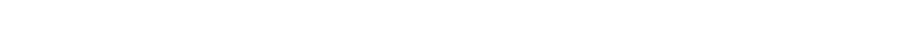

In [ ]:
import marimo as mo

In [ ]:
# ──────────────────────────────────────────────────────────────────────────
# FULL MODE — scaled to ~50,000 training steps with higher LR for faster convergence.
# Run this cell, then run the rest of the notebook (Run All).
# ──────────────────────────────────────────────────────────────────────────
import os as _os
import json as _json

_os.environ["VRL_MODE"] = "full"
_os.environ["VRL_ENV"] = "pursuit"          # or "reacher" for the second environment

# No time budget — train each agent to completion in one go.
_os.environ["VRL_TRAIN_BUDGET"] = "0"

# Override the full-mode Cfg fields to get ~50,000 training steps with a higher
# learning rate for faster convergence, while keeping evaluation budgets reduced.
_os.environ["VRL_OVERRIDE"] = _json.dumps({
    "train_steps": 50000,
    "seed_steps": 1000,
    "std_decay_steps": 25000,
    "agents": ["drqv2", "svea"],        # 6 agents (2 recipes x 3 seeds) — noaug removed (never learns at 50K)
    "agent_seeds": [0, 1, 2],            # 3 seeds per recipe
    "train_gate_success": 0.2,           # agents must achieve 20% clean success
    "lr": 3e-4,                          # 3x the full-mode default for faster learning
    "eps_per_cell": 20,               # reduced from 100
    "ref_eps": 20,                    # reduced from 60
    "ref_max_rows": 2000,
    "boot_B": 500,                    # reduced from 2000
    "cal_clean_eps": 50,             # reduced from 200
    "tta_eps": 20,                   # reduced from 100
    "tta_agents": 2,                 # reduced from 5
    "hidden": 256,                   # reduced from 1024
    "batch": 128,                    # reduced from 256
    "img": 48,                       # reduced from 64
    "ep_len": 50,                    # reduced from 100
    "eval_every_eps": 20,            # reduced from 50
    "n_eval_eps": 10                  # reduced from 20
})

_full_cfg_info = """
============================================================
  FULL MODE (scaled to 50K steps, lr=3e-4)
============================================================
  Mode:           full
  Train steps:    50,000 per agent
  LR:             3e-4 (3x default for faster convergence)
  Agents:         6 (2 recipes x 3 seeds) — noaug removed
  Image:          48x48 RGB, 3 stacked frames
  Episode len:    50 steps
  Hidden dim:     256
  Batch:          128
  Shift kinds:    5 (background, noise, distractor, viewpoint, color)
  Severities:     11 (0.0, 0.1, ..., 1.0)
  Episodes/cell:  20
  Boot B:         500
  TTA:            2 agents, 20 eps, 3 severities

  Expected output: results_full_pursuit/
  Run the replication cell last to combine with reacher results.
============================================================
"""
print(_full_cfg_info)
print("Now run the rest of the notebook (Run All).")
print("Overrides applied for a faster full run with ~50K training steps and lr=3e-4.")



  FULL MODE (scaled to 50K steps, lr=3e-4)
  Mode:           full
  Train steps:    50,000 per agent
  LR:             3e-4 (3x default for faster convergence)
  Agents:         6 (2 recipes x 3 seeds) — noaug removed
  Image:          48x48 RGB, 3 stacked frames
  Episode len:    50 steps
  Hidden dim:     256
  Batch:          128
  Shift kinds:    5 (background, noise, distractor, viewpoint, color)
  Severities:     11 (0.0, 0.1, ..., 1.0)
  Episodes/cell:  20
  Boot B:         500
  TTA:            2 agents, 20 eps, 3 severities

  Expected output: results_full_pursuit/
  Run the replication cell last to combine with reacher results.

Now run the rest of the notebook (Run All).
Overrides applied for a faster full run with ~50K training steps and lr=3e-4.


# Forecasting the Competence Boundary of Visual Control Policies Without Rollouts

A pre-registered study with theory, code and decision rules.
Project: vision-rl. Revised after the ICVGIP reviews of submission 491.

## 1. The research problem

**Setting.** A pixel-based policy $\pi$ acts in a task. A deployment may change how the world is *rendered* (background, sensor noise, distractors, camera viewpoint, color) without changing the task. Let $T^{\kappa}_s$ be a controlled shift of kind $\kappa$ and severity $s\in[0,1]$, with $T_0^{\kappa}=\mathrm{id}$. Let $\mathrm{SR}^{\kappa}_{\pi}(s)$ be the success rate of $\pi$ when it sees $T^{\kappa}_s$ of every frame.

**Competence boundary.** The *critical severity* is
$$ s^{*}_{\pi,\kappa}\;=\;\inf\{\,s\in[0,1]\;:\;\mathrm{SR}^{\kappa}_{\pi}(s)\le \tfrac12\,\mathrm{SR}^{\kappa}_{\pi}(0)\,\},$$
set to $1$ (and flagged as censored) if the set is empty. It is the severity at which the policy has lost half of its clean competence. It is measured in the units of the shift, so an error of $0.1$ means "wrong by ten percent of the severity range".

**Information constraint.** A forecaster $\mathcal F$ receives the policy's weights, a small set $D_0$ of **clean** episodes, and the ability to *render* any shift on recorded clean frames. It receives **no rollout under any shift with $s>0$**. It returns $\hat s_{\pi,\kappa}$.

**The three tasks.**
* **A. Forecast.** Make $|\hat s-s^{*}|$ small.
* **B. Rank.** For a set $\Pi$ of policies (different training recipes and seeds), order them by $\hat s$. Quality is Kendall's $\tau$ between $\hat s$ and $s^{*}$ over $\Pi$.
* **C. Select.** Pick $\hat\pi=\arg\max_{\pi}\hat s_\pi$. Quality is the *selection regret* $\max_\pi s^*_\pi-s^*_{\hat\pi}$.

**Evaluation protocol.** Calibration and test use disjoint episodes (held-out seeds). The strict protocol also holds out the whole shift kind. Policies are compared on identical episode seeds.

**Why this is worth solving.** Today the robustness of a visual policy or of a training recipe is learned by running it under every shift that might occur, which is slow, and unsafe on hardware. A forecast that ranks recipes before deployment turns that into a cheap pre-screen. It also tells practitioners *how far* a shift can go before the policy fails, which a yes-or-no failure alarm cannot.

## 2. Position relative to prior work

Evidence: a Consensus audit run on 1 Nov 2026 (full report saved alongside this notebook), plus my full-text reads of KAGE-Bench, the ProcGen gap paper, VLA-Scope, the OpenVLA early-warning paper, OOD-RL-Bench, Predictive Red Teaming and the visual MBRL shift-detection paper.

| Closest work | What it does | What it does not do |
|---|---|---|
| Predictive Red Teaming (Majumdar et al., 2025) | Predicts success under visual edits without hardware rollouts, using policy-embedding distance, for imitation policies | No severity axis, no critical severity, no ranking of policies by regret, no pixel-RL agents |
| FIPER (Römer et al., 2025) | Policy-embedding drift plus action entropy to predict failure at runtime; shows pure OOD detectors fire on benign shifts | Needs execution; imitation policies; no offline severity forecast |
| Farid et al. (RSS 2022) | PAC-Bayes guarantees on false-positive and false-negative rates of failure predictors for vision-based control | Binary failure prediction over environments; no continuous boundary |
| Burns et al. (2023) | Predicts the zero-shot ranking of pre-trained visual encoders from emergent segmentation | Fixed encoders; no critical severity; no regret |
| Lee and Har (2026) | Action disagreement under weight perturbation to flag failure in VLA models | Binary detection during rollouts |
| OOD-RL-Bench (2026), JEPA shift detection (2026) | Detect that a shift is present | Do not predict policy failure; state-based or detection only |
| UCB-DrAC family (Raileanu et al., 2021) | Selects augmentations using returns collected during training | Requires rollouts; no forecast |

**Verdict.** Each ingredient has precedent. What I did not find, after the Consensus audit and my own searches, is the combination stated above: a rollout-free forecast of the critical severity along a continuous shift axis, scored in severity units, used to rank pixel-RL training recipes with a selection-regret metric, together with the two results in Section 4. This is a verdict from a limited search, not a proof of novelty; the three works to read most carefully before submission are Predictive Red Teaming, FIPER and Burns et al.

## 3. Contributions, each testable

1. **A formal problem** (competence-boundary forecasting) with metrics in severity units: forecast error, Kendall $\tau$, selection regret.
2. **Proposition 1 (non-identifiability).** No forecast computed from observation statistics alone can rank all policies. Policy-conditional signals are necessary.
3. **Proposition 2 (prevalence).** AUROC of a failure predictor equals $\tfrac12+(a-\tfrac12)J(q)$, where $J$ is a Youden index that changes with the regime mix $q$. AUROC is prevalence-invariant only in a degenerate case. This gives a *prevalence-portable* three-number report.
4. **An estimator and baselines,** evaluated under a held-out protocol with prevalence, false alarms and paired statistics.
5. **A pre-registered empirical study** across training recipes, shift families and two environments (Section 5), with every decision rule and a replication rule fixed before data.

## 4. Theory

### Proposition 1 (non-identifiability of policy-agnostic scores)

*Let $D$ be any score computed from the clean and shifted observation laws $(P_0,P_s)$ alone, without access to $\pi$. Suppose a shift component $z$ is task-irrelevant and takes a fixed value $z_0$ in clean observations. Then for any $s_0\in(0,1)$ there exist two policies $\pi_a,\pi_b$ with identical clean behavior, hence identical $P_0$, $\mathrm{SR}(0)$ and identical $D_s$ for all $s$, such that $s^*_{\pi_a}\le s_0$ while $s^*_{\pi_b}=1$ (censored).*

*Proof.* Take any competent policy $\pi_0$. Let $\pi_b=\pi_0\circ\rho$ where $\rho$ removes the dependence on $z$ (for example it overwrites the nuisance channel by its clean value). Let $\pi_a(o)=\pi_0(o)+\Delta(z(o))$ where $\Delta(z_0)=0$ and $\Delta(z)$ is a bounded action offset large enough to break tracking whenever $|z-z_0|\ge \phi(s_0)$, with $\phi$ the shift's displacement at severity $s_0$. On clean data $z\equiv z_0$, so both policies act as $\pi_0$ and have the same clean success rate. The observations are the same random variables for both policies, so any $D$ that is a functional of $(P_0,P_s)$ gives the same value. Under the shift, $\pi_b$ is unaffected, so $\mathrm{SR}_b(s)=\mathrm{SR}_b(0)$ for all $s$ and $s^*_b=1$; $\pi_a$ collapses once $|z-z_0|\ge\phi(s_0)$, so $s^*_a\le s_0$. $\square$

*Consequence.* Raw pixel distance and any fixed-feature distance (including an untrained encoder) cannot rank policies by $s^*$. The notebook tests this empirically (H4) on policies trained with different recipes.

### Proposition 2 (what AUROC measures under mixed regimes)

*Assume the population is a mixture of a plateau regime (share $1-q$, failure probability $f_p$) and a cliff regime (share $q$, failure probability $f_c$). The score $S$ depends on the regime only ($S\perp Y\mid R$) and is continuous within a regime. Let $a=P(S_{c}>S_{p})$ for independent draws. Let $\alpha^+=P(R{=}c\mid Y{=}1)$ and $\alpha^-=P(R{=}c\mid Y{=}0)$. Then*
$$\mathrm{AUROC}\;=\;\tfrac12+\bigl(a-\tfrac12\bigr)\,\bigl(\alpha^+-\alpha^-\bigr),\qquad \alpha^{+}=\frac{q f_c}{q f_c+(1-q)f_p},\quad \alpha^{-}=\frac{q(1-f_c)}{q(1-f_c)+(1-q)(1-f_p)}.$$

*Proof.* Draw a random failure and an independent random success. By $S\perp Y\mid R$, each one's score has the law of $S$ given its regime, and its regime is cliff with probability $\alpha^+$ and $\alpha^-$ respectively. Condition on the two regimes. A (cliff, plateau) pair has the failure scoring higher with probability $a$, a (plateau, cliff) pair with probability $1-a$, and a same-regime pair with probability $\tfrac12$ by exchangeability and continuity. Summing gives
$\alpha^+(1-\alpha^-)a+(1-\alpha^+)\alpha^-(1-a)+\tfrac12[\alpha^+\alpha^-+(1-\alpha^+)(1-\alpha^-)]$, which simplifies to the stated form. $\square$

**Corollaries.** (i) $\alpha^+-\alpha^-$ is the Youden index (TPR minus FPR) of the *oracle regime indicator* used as a failure predictor. (ii) For $a\ne\tfrac12$ the AUROC is independent of $q$ if and only if $(f_p,f_c)=(0,1)$ or $(1,0)$, that is, only when the regime fully determines the outcome. (iii) If $f_p>0$ then $\mathrm{AUROC}\to\tfrac12$ as $q\to0$. (iv) The AUPRC of a random score equals the prevalence $qf_c+(1-q)f_p$.

*Consequence.* A bare AUROC is not portable between studies with different regime mixes. The triple $(a,f_p,f_c)$ is. Both propositions are checked numerically by the audit tests, and Section 22 tests the portability claim on data.

## 5. Pre-registered hypotheses and decision rules

| ID | Hypothesis | Decision rule (thresholds are in `PREREG`) |
|---|---|---|
| H0 | The agents solve the clean task | Training gate on clean success |
| H1 | Failure is abrupt | In at least 50% of curves with a drop of 0.3 or more, cliffness is at least 0.5 |
| H2 | The critical severity is forecastable | Median absolute error at most 0.15 severity units, and a lower error than both policy-agnostic baselines with the 95% interval of the paired gain excluding 0 |
| H3 | Policies can be ranked and selected | Mean Kendall $\tau\ge0.5$ and mean selection regret at most 0.10 |
| H4 | Policy-conditional beats policy-agnostic | $\tau$ gap of at least 0.3 (tests Proposition 1) |
| H5 | The $(a,f_p,f_c)$ report is prevalence-portable | Mean absolute AUROC prediction error at most 0.05 (tests Proposition 2) |
| H6 | Safeguarded TTA beats naive TTA (secondary) | Holm-adjusted $p<0.05$ with accepted updates |
| H7 | False alarms are controlled | Clean false-alarm rate at most twice nominal |

**Replication rule.** H1 to H5 count as general findings only if they are SUPPORTED in at least two environments (`PREREG['min_envs_supported']`). A result in one environment is reported as a result for that environment. A hypothesis that reads NOT SUPPORTED is reported as such. The fingerprint printed by the next cell lets you time-stamp the rules before running pilot or full.

## 6. What a journal reviewer will still ask, and what this notebook does not yet do

| Requirement | Status |
|---|---|
| At least three environments, one of them a standard benchmark | Two native environments are implemented and contract-tested: pursuit and a 2-link reacher (a DMControl-style analogue built without MuJoCo; it is **not** the DeepMind Control Suite). The Procgen CoinRun adapter is written but not executed. No standard benchmark has been run |
| At least five policy seeds per recipe | `agent_seeds` in `full` mode is five |
| Modern and pretrained encoders, TACO, D.Va | **Not implemented** (needs the authors' code; I have not read those papers) |
| Real-image or real-robot shift | **Not covered** |
| Results | **None yet.** Smoke mode checks plumbing; pilot and full have not been run |

Whether this becomes a journal paper depends on H1 to H5 holding on real runs across more than one environment. The code is built so that a negative outcome is reportable as a finding (for example, "policy-conditional signals do not rank policies"), which many venues will accept if the study is sound.

## 7. How to run

```bash
pip install torch numpy pandas matplotlib scikit-learn jinja2
VRL_MODE=smoke VRL_ENV=pursuit jupyter nbconvert --to notebook --execute this.ipynb   # minutes on one CPU core, plumbing only
VRL_MODE=smoke VRL_ENV=reacher ...                                                    # the second environment
VRL_MODE=pilot VRL_ENV=pursuit ...   then   VRL_MODE=pilot VRL_ENV=reacher ...        # a real but small study (GPU advised)
VRL_MODE=full  VRL_ENV=pursuit ...   then   VRL_MODE=full  VRL_ENV=reacher ...        # the configuration intended for the paper
```

Run the notebook once per environment, from the same directory. Any `Cfg` field can be overridden at launch, for example `VRL_OVERRIDE='{"train_steps": 60000}'`. On a host with time limits set `VRL_TRAIN_BUDGET=<seconds>`: training pauses and resumes from its saved state when the training cell is run again, and finished sweeps are cached per agent. Each run writes to `results_<mode>_<env>/`, and the last analysis cell reads both folders to apply the replication rule.

| Item | Tested here |
|---|---|
| Environment, shifts, metrics, statistics, theory identities | Unit-tested by the audit cell |
| Whole notebook in smoke mode | Runs end to end |
| DrQ-v2 learning | 7,000 steps on one CPU core: clean CLE 22.7 px to about 10 px (random floor 12.4 px), success 0.10. Learning, but slow |
| Calibration, per-agent gate, verdict preconditions, H2 interval, H6 engagement check | **Written after the last execution and only syntax-checked.** Run smoke mode first and check that every audit test passes |
| Pilot and full | Not run |
| Reacher environment | Contract-tested (determinism, masks, shifts, post-hoc equals closed loop). DrQ-v2 did **not** learn it within 6,000 CPU steps (CLE 13 to 17 px against a random floor of 14.4 px), so pilot and full give it three times the budget and the training gate stops the study if it still fails |
| PPO appendix | Runs on the discrete task (smoke) |
| Procgen adapter | Written, not executed |

In smoke mode the agents are untrained, so every statistic is a plumbing check.

> **Revision after the ICVGIP reviews.** See the section "Revision notes" after the audit tests. Outputs saved below predate those edits.


## 8. Setup and configuration

`Cfg` holds every number that defines the study. Success and collapse are defined once: success means the episode-mean center-localization error (CLE) is below `success_cle_px`; floor collapse means it is at least `collapse_frac` times the CLE of a uniform-random policy. Seed ranges for training, reference, test and curve evaluation are disjoint.

In [ ]:
import os, json, math, time, copy, hashlib, platform, warnings, subprocess, collections, sys
from dataclasses import dataclass, asdict, replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

# ---------------------------------------------------------------------------
# Run mode. smoke: plumbing check in minutes. sandbox: a small real study that fits one CPU core. pilot: a larger study.
# full: the configuration intended for the paper.  Set VRL_MODE before launching.
# ---------------------------------------------------------------------------
MODE = "full"  # hardcoded: full study (200K steps, 15 policies, 11 severities)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ENV_NAME = os.environ.get("VRL_ENV", "pursuit")
OUT = os.environ.get("VRL_OUT", f"results_{MODE}_{ENV_NAME}")
os.makedirs(OUT, exist_ok=True)
os.makedirs(os.path.join(OUT, "ckpt"), exist_ok=True)
os.makedirs(os.path.join(OUT, "figs"), exist_ok=True)
os.makedirs(os.path.join(OUT, "tables"), exist_ok=True)


@dataclass(frozen=True)
class Cfg:
    mode: str = "smoke"
    env: str = "pursuit"             # pursuit | reacher
    # ---- environment -------------------------------------------------------
    img: int = 32
    ep_len: int = 20
    n_stack: int = 3
    max_step_px: float = 2.0
    target_speed: float = 0.8
    agent_radius: float = 2.0
    link_frac: float = 0.30          # reacher: link length as a fraction of the image width
    max_dtheta: float = 0.35         # reacher: largest joint-angle change per step (radians)
    # Success and collapse are defined ONCE, here, and used everywhere.
    success_cle_px: float = 5.0      # success iff episode-mean CLE < this (strict)
    collapse_frac: float = 0.8       # floor collapse iff episode-mean CLE >= frac * random-policy CLE
    # ---- agent training ----------------------------------------------------
    train_steps: int = 800
    seed_steps: int = 200
    batch: int = 32
    feature_dim: int = 32
    hidden: int = 64
    lr: float = 3e-4
    discount: float = 0.99
    n_step: int = 3
    tau: float = 0.01
    update_every: int = 2
    std_start: float = 1.0
    std_end: float = 0.1
    std_decay_steps: int = 500
    std_clip: float = 0.3
    aug_pad: int = 3
    eval_every_eps: int = 10
    n_eval_eps: int = 5
    svea_alpha: float = 0.5
    svea_beta: float = 0.5
    train_gate_success: float = 0.0  # training gate on clean success (0 disables)
    # ---- study grid --------------------------------------------------------
    agents: tuple = ("drqv2", "svea", "noaug")
    agent_seeds: tuple = (0,)
    shift_kinds: tuple = ("background", "noise", "distractor", "viewpoint", "color_gain")
    severities: tuple = (0.0, 0.5, 1.0)
    eps_per_cell: int = 6
    # ---- forecasting probes ------------------------------------------------
    knn_k: int = 5
    ref_eps: int = 8
    ref_max_rows: int = 2000
    frame_stride: int = 1
    clean_fpr: float = 0.05
    ema: float = 0.5
    grassmann_ks: tuple = (3, 5)
    boot_B: int = 200
    cal_clean_eps: int = 10          # clean-only episodes used ONLY to calibrate thresholds (label-free and cheap)
    # ---- test-time adaptation ----------------------------------------------
    tta_kinds: tuple = ("background", "noise")
    tta_severities: tuple = (1.0,)
    tta_eps: int = 6
    tta_lr: float = 1e-4
    tta_mm_weight: float = 1.0
    tta_accept_delta: float = 0.15
    tta_buffer: int = 8
    tta_clean_batch: int = 32
    tta_agents: int = 99             # run the (slow, secondary) TTA study on the first N agents only
    # ---- additions driven by the ICVGIP reviews ---------------------------------------------------
    extra_recipes: tuple = ()        # e.g. ("taco",): training recipes in addition to cfg.agents (TACO-style, simplified)
    taco_dim: int = 64
    taco_weight: float = 1.0
    taco_temp: float = 0.1
    latency_reps: int = 30           # repetitions for the latency protocol (median and p90 are reported)
    tta_perm: int = 5000             # sign-flip permutations for the paired mean-CLE test


def make_cfg(mode, env="pursuit"):
    cfg = _make_cfg(mode, env)
    if env == "reacher" and mode != "smoke":      # inverse kinematics from pixels needs a larger budget than pursuit
        cfg = replace(cfg, train_steps=3 * cfg.train_steps, std_decay_steps=3 * cfg.std_decay_steps, seed_steps=2 * cfg.seed_steps)
    return cfg


def _make_cfg(mode, env="pursuit"):
    if mode == "smoke":
        return Cfg(mode="smoke", env=env)
    if mode == "sandbox":      # sized for ONE CPU core: small images, short episodes, 3 recipes x 2 seeds
        return Cfg(mode="sandbox", env=env, img=24, ep_len=24, max_step_px=2.0, target_speed=0.6, success_cle_px=3.5,
                   train_steps=16000, seed_steps=480, batch=32, feature_dim=32, hidden=64, lr=3e-4, std_decay_steps=8000,
                   aug_pad=3, eval_every_eps=40, n_eval_eps=8, train_gate_success=0.4, agent_seeds=(0, 1),
                   severities=(0.0, 0.2, 0.4, 0.6, 0.8, 1.0), eps_per_cell=24, ref_eps=16, ref_max_rows=1500, frame_stride=2,
                   grassmann_ks=(3, 5), boot_B=300, cal_clean_eps=40, tta_kinds=("noise", "background"), tta_severities=(0.8,), tta_eps=8,
                   tta_agents=2, tta_lr=1e-3)
    if mode == "pilot":
        return Cfg(mode="pilot", env=env, img=48, ep_len=50, train_steps=20000, seed_steps=1000, batch=128,
                   feature_dim=50, hidden=256, lr=1e-4, std_decay_steps=15000, aug_pad=4,
                   eval_every_eps=20, n_eval_eps=10, train_gate_success=0.5,
                   agent_seeds=(0, 1, 2), severities=tuple(np.round(np.linspace(0, 1, 11), 2)),
                   eps_per_cell=40, ref_eps=30, frame_stride=5, grassmann_ks=(5, 10, 20),
                   boot_B=1000, cal_clean_eps=100, tta_eps=30, tta_severities=(0.6, 0.8, 1.0), tta_agents=3, tta_lr=1e-3)
    if mode == "full":
        return Cfg(mode="full", env=env, img=64, ep_len=100, train_steps=200000, seed_steps=4000, batch=256,
                   feature_dim=50, hidden=1024, lr=1e-4, std_decay_steps=100000, aug_pad=4,
                   eval_every_eps=50, n_eval_eps=20, train_gate_success=0.7,
                   agent_seeds=(0, 1, 2, 3, 4), severities=tuple(np.round(np.linspace(0, 1, 11), 2)),
                   eps_per_cell=100, ref_eps=60, ref_max_rows=4000, frame_stride=5,
                   grassmann_ks=(5, 10, 20), boot_B=2000, cal_clean_eps=200, tta_eps=100,
                   tta_severities=(0.6, 0.8, 1.0), tta_agents=5, tta_lr=1e-3)
    raise ValueError(mode)


CFG = make_cfg(MODE, ENV_NAME)
# Any Cfg field can be overridden at launch without editing code, for example
#   VRL_OVERRIDE='{"train_steps": 40000, "eps_per_cell": 60}'
_ov = json.loads(os.environ.get("VRL_OVERRIDE", "{}"))
if _ov:
    CFG = replace(CFG, **{k: (tuple(v) if isinstance(v, list) else v) for k, v in _ov.items()})
    print("overrides applied:", _ov)
# To make training resumable (pause/resume across runs), set VRL_TRAIN_BUDGET=<seconds>
# in your environment before launching, e.g. VRL_TRAIN_BUDGET=600
# Then re-run the training cell each time it pauses until all 15 agents are done.
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
print("mode:", CFG.mode, "| environment:", CFG.env, "| device:", DEVICE, "| output:", OUT)
print("torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

# Seed ranges. Disjoint by construction so that training, calibration and test never share an episode.
SEEDS = dict(train=10_000, ref=20_000, test=30_000, eval_curve=40_000, floor=50_000, cal=60_000)


def seed_for(split, i, agent_seed=0):
    return SEEDS[split] + 1000 * int(agent_seed) * (split == "train") + int(i)

overrides applied: {'train_steps': 50000, 'seed_steps': 1000, 'std_decay_steps': 25000, 'agents': ['drqv2', 'svea'], 'agent_seeds': [0, 1, 2], 'train_gate_success': 0.2, 'lr': 0.0003, 'eps_per_cell': 20, 'ref_eps': 20, 'ref_max_rows': 2000, 'boot_B': 500, 'cal_clean_eps': 50, 'tta_eps': 20, 'tta_agents': 2, 'hidden': 256, 'batch': 128, 'img': 48, 'ep_len': 50, 'eval_every_eps': 20, 'n_eval_eps': 10}
mode: full | environment: pursuit | device: cuda | output: results_full_pursuit
torch 2.11.0+cu130 | numpy 2.4.6 | pandas 3.0.6


### Pre-registration fingerprint

The decision rules of Section 5, frozen in code.

In [ ]:
# ======================= Pre-registered decision rules (fix these BEFORE looking at any result) =======================
PREREG = dict(
    version="1.0",
    # H0 training gate: agents must solve the clean task (see Cfg.train_gate_success)
    h1_min_cliffness=0.5, h1_min_total_drop=0.3, h1_min_share=0.5,        # abrupt failure is common
    h2_max_median_abs_err=0.15, h2_require_beats=("knn_pixel", "knn_random"), h2_ci_excludes_zero=True,   # forecast error in severity units; paired gain over baselines
    h3_min_tau=0.5, h3_max_regret=0.10,                                   # policy ranking and selection
    h4_min_tau_gap=0.3,                                                   # policy-conditional beats policy-agnostic
    h5_max_auroc_error=0.05,                                              # prevalence-portable summary
    h6_alpha=0.05,                                                        # secondary: safeguarded TTA versus naive TTA
    h7_max_false_alarm_factor=2.0,                                        # clean false alarms within 2x nominal
    min_envs_supported=2,                                                 # H2 to H5 are claimed as general only if they hold in this many environments
    proposed="knn_policy", agnostic=("knn_pixel", "knn_random"), policy_conditional=("knn_policy", "act_disagree"),
)
PREREG_HASH = hashlib.sha256(json.dumps(PREREG, sort_keys=True).encode()).hexdigest()[:16]
print("Pre-registration fingerprint:", PREREG_HASH)
print("Commit this notebook (or paste this fingerprint into a time-stamped registry such as OSF) BEFORE running pilot or full.")

Pre-registration fingerprint: 044430f25ed77702
Commit this notebook (or paste this fingerprint into a time-stamped registry such as OSF) BEFORE running pilot or full.


## 9. Environment, outcome definitions and rollouts

The target's motion depends only on the episode seed, so any two policies run on the same seed face the same target trajectory, which makes paired comparison possible. The renderer returns an entity mask, so ground-truth segmentation is exact.

In [ ]:
class PursuitEnv:
    """Visual pursuit task.
    A red disc (the agent) is moved by a 2-D velocity command and must stay on a green disc (the target).
    The target performs a smooth random walk that depends ONLY on the episode seed, so two policies run on the
    same seed face an identical target trajectory (this is what makes paired evaluation possible).
    The renderer also returns an entity mask (0 background, 1 agent, 2 target, 3 distractor),
    so ground-truth segmentation comes from the simulator and not from a colour threshold."""
    BG = np.array([26, 26, 26], np.float32) / 255.0
    AGENT = np.array([230, 26, 26], np.float32) / 255.0
    TARGET = np.array([26, 230, 26], np.float32) / 255.0

    def __init__(self, cfg):
        self.c = cfg
        H = cfg.img
        self.yy, self.xx = np.mgrid[0:H, 0:H].astype(np.float32)

    def reset(self, seed):
        c, H = self.c, self.c.img
        r = np.random.default_rng([int(seed), 7])
        self.trng = np.random.default_rng([int(seed), 11])      # target stream, independent of the agent
        m = 6.0
        self.p = r.uniform(m, H - m, 2).astype(np.float32)
        self.q = r.uniform(m, H - m, 2).astype(np.float32)
        self.heading = float(r.uniform(0, 2 * np.pi))
        self.t = 0
        return self.render()

    def _disc(self, c, rad):
        return (self.xx - c[0]) ** 2 + (self.yy - c[1]) ** 2 <= rad ** 2

    def render(self):
        H = self.c.img
        img = np.empty((H, H, 3), np.float32)
        img[:] = self.BG
        mask = np.zeros((H, H), np.int8)
        d = self._disc(self.q, self.c.agent_radius); img[d] = self.TARGET; mask[d] = 2
        d = self._disc(self.p, self.c.agent_radius); img[d] = self.AGENT; mask[d] = 1
        return img, mask

    def step(self, action):
        c, H = self.c, self.c.img
        a = np.clip(np.asarray(action, np.float32), -1, 1)
        self.p = np.clip(self.p + c.max_step_px * a, c.agent_radius, H - c.agent_radius)
        self.heading += float(self.trng.normal(0, 0.3))
        v = c.target_speed * np.array([np.cos(self.heading), np.sin(self.heading)], np.float32)
        q = self.q + v
        lo, hi = c.agent_radius, H - c.agent_radius
        for k in range(2):                                      # reflect at the walls
            if q[k] < lo or q[k] > hi:
                q[k] = np.clip(q[k], lo, hi)
                self.heading = (np.pi - self.heading) if k == 0 else (-self.heading)
        self.q = q.astype(np.float32)
        self.t += 1
        cle = float(np.linalg.norm(self.p - self.q))
        reward = -cle / (H / 2.0)
        img, mask = self.render()
        return img, mask, reward, cle, self.t >= c.ep_len


# ---- single source of truth for outcome definitions -----------------------------------------------
def is_success(mean_cle, cfg):
    return bool(mean_cle < cfg.success_cle_px)


def is_collapse(mean_cle, cfg, floor_cle):
    return bool(mean_cle >= cfg.collapse_frac * floor_cle)


def to_u8(frame):                         # float HWC in [0,1] -> uint8 CHW
    return (np.clip(frame, 0, 1) * 255.0 + 0.5).astype(np.uint8).transpose(2, 0, 1)


def from_u8(u8):                          # uint8 CHW -> float HWC in [0,1]
    return u8.astype(np.float32).transpose(1, 2, 0) / 255.0


def make_stacks(view_u8, n_stack):
    """(T+1,3,H,W) -> (T+1, 3*n_stack, H, W); stack t holds frames t-n+1..t, clipped at the episode start."""
    T1 = view_u8.shape[0]
    idx = np.clip(np.arange(T1)[:, None] - np.arange(n_stack - 1, -1, -1)[None, :], 0, None)
    return view_u8[idx].reshape(T1, -1, *view_u8.shape[2:])


def rollout(env, act_fn, seed, cfg, shift=None, record=False):
    """Run one episode. act_fn maps a stacked uint8 observation (3*n_stack,H,W) to an action in [-1,1]^2.
    If `shift` is given, the policy sees shifted frames while CLE is always measured in the true state.
    record=True keeps the CLEAN frames and entity masks so shifts can be injected post hoc."""
    f, m = env.reset(seed)
    clean = [to_u8(f)]; masks = [m.copy()]
    view = [to_u8(f if shift is None else shift(f, m, 0)[0])]
    stack = collections.deque([view[0]] * cfg.n_stack, maxlen=cfg.n_stack)
    cles, rews, acts = [], [], []
    for t in range(1, cfg.ep_len + 1):
        obs = np.concatenate(list(stack), 0)
        a = np.asarray(act_fn(obs), np.float32)
        f, m, r, cle, done = env.step(a)
        v = to_u8(f if shift is None else shift(f, m, t)[0])
        stack.append(v); view.append(v)
        clean.append(to_u8(f)); masks.append(m.copy())
        cles.append(cle); rews.append(r); acts.append(a)
    mean_cle = float(np.mean(cles))
    rec = dict(seed=int(seed), mean_cle=mean_cle, ret=float(np.sum(rews)), cle_t=np.array(cles, np.float32),
               success=is_success(mean_cle, cfg), view_u8=np.stack(view), actions=np.stack(acts),
               rewards=np.array(rews, np.float32))
    if record:
        rec["clean_u8"] = np.stack(clean); rec["masks"] = np.stack(masks)
    return rec

### Second environment: a 2-link reacher

The reacher is structurally different from pursuit: joint-angle control, an arm drawn as capsules, a static target. It honours the same contract (rollout, mask ids, outcome definitions), so every shift, probe and analysis below runs on it unchanged. It is a DMControl-style analogue built in numpy. It is **not** the DeepMind Control Suite. Select it with `VRL_ENV=reacher`.

In [ ]:
class ReacherEnv:
    """Second task, structurally different from pursuit: a 2-link planar arm with its base at the image center.
    Actions are joint-angle velocities in [-1,1]^2. The target is a static disc placed in the arm's reachable annulus
    (it depends only on the episode seed). The task is to bring the fingertip onto the target and keep it there.
    CLE is the fingertip-to-target distance in pixels. The renderer returns an entity mask (0 background, 1 arm, 2 target),
    so the same shifts, probes and outcome definitions apply unchanged. This is a DMControl-STYLE analogue implemented
    without MuJoCo; it is NOT the DeepMind Control Suite and must not be described as such."""
    BG, AGENT, TARGET = PursuitEnv.BG, PursuitEnv.AGENT, PursuitEnv.TARGET

    def __init__(self, cfg):
        self.c = cfg; H = cfg.img
        self.yy, self.xx = np.mgrid[0:H, 0:H].astype(np.float32)
        self.base = np.array([H / 2.0, H / 2.0], np.float32)
        self.L = cfg.link_frac * H

    def reset(self, seed):
        c, H = self.c, self.c.img
        r = np.random.default_rng([int(seed), 21])
        self.th = r.uniform(-np.pi, np.pi, 2).astype(np.float32)
        rad, ang = r.uniform(0.4, 1.8) * self.L, r.uniform(0, 2 * np.pi)
        self.q = np.clip(self.base + rad * np.array([np.cos(ang), np.sin(ang)], np.float32), 4.0, H - 4.0).astype(np.float32)
        self.t = 0
        return self.render()

    def _joints(self):
        a1, a2 = float(self.th[0]), float(self.th[0] + self.th[1])
        elbow = self.base + self.L * np.array([np.cos(a1), np.sin(a1)], np.float32)
        tip = elbow + self.L * np.array([np.cos(a2), np.sin(a2)], np.float32)
        return elbow, tip

    def _capsule(self, A, B, w):
        AB = B - A; denom = float(AB @ AB) + 1e-9
        t = np.clip(((self.xx - A[0]) * AB[0] + (self.yy - A[1]) * AB[1]) / denom, 0.0, 1.0)
        return (self.xx - (A[0] + t * AB[0])) ** 2 + (self.yy - (A[1] + t * AB[1])) ** 2 <= w ** 2

    def render(self):
        H = self.c.img
        img = np.empty((H, H, 3), np.float32); img[:] = self.BG
        mask = np.zeros((H, H), np.int8)
        d = (self.xx - self.q[0]) ** 2 + (self.yy - self.q[1]) ** 2 <= 2.0 ** 2
        img[d] = self.TARGET; mask[d] = 2
        elbow, tip = self._joints()
        for A, B in ((self.base, elbow), (elbow, tip)):
            d = self._capsule(A, B, 1.3); img[d] = self.AGENT; mask[d] = 1
        d = (self.xx - tip[0]) ** 2 + (self.yy - tip[1]) ** 2 <= 2.0 ** 2
        img[d] = self.AGENT; mask[d] = 1
        return img, mask

    def step(self, action):
        c, H = self.c, self.c.img
        a = np.clip(np.asarray(action, np.float32), -1, 1)
        self.th = ((self.th + c.max_dtheta * a + np.pi) % (2 * np.pi) - np.pi).astype(np.float32)
        self.t += 1
        _, tip = self._joints()
        cle = float(np.linalg.norm(tip - self.q))
        img, mask = self.render()
        return img, mask, -cle / (H / 2.0), cle, self.t >= c.ep_len


ENV_REGISTRY = {"pursuit": PursuitEnv, "reacher": ReacherEnv}


def make_env(cfg):
    return ENV_REGISTRY[cfg.env](cfg)

## 10. Controlled observation shifts

A shift acts on the rendered frame and mask only. Its random parameters are fixed per episode and seeded by the episode, so a viewpoint rotation never changes frame to frame and the same episode renders identically in the closed loop and post hoc. Severity 0 is the exact identity.

In [ ]:
KIND_ID = {"background": 1, "noise": 2, "distractor": 3, "viewpoint": 4, "color_gain": 5}


class Shift:
    """A controlled observation shift of a given kind and severity s in [0,1].
    * The shift acts on the rendered frame and entity mask only; dynamics and reward are untouched.
    * All random parameters are drawn from an RNG seeded by (episode seed, kind), so they are FIXED within an
      episode and identical wherever the same episode is re-rendered (closed loop or post hoc).
    * Per-frame randomness (sensor noise) is seeded by (episode seed, kind, frame index).
    * severity 0 is the exact identity."""

    def __init__(self, kind, severity, ep_seed, img):
        assert kind in KIND_ID, kind
        self.kind, self.s, self.seed, self.img = kind, float(severity), int(ep_seed), int(img)
        r = np.random.default_rng([self.seed, KIND_ID[kind], 99])
        if kind == "background":
            self.col = r.uniform(0, 1, 3).astype(np.float32)
        elif kind == "distractor":
            k = int(round(self.s * 5)); self.k = k
            n = max(k, 1)
            self.pos0 = r.uniform(0, img, (n, 2)); self.vel = r.uniform(-1.2, 1.2, (n, 2))
            self.rad = r.uniform(2.0, 3.5, n); self.dcol = r.uniform(0, 1, (n, 3)).astype(np.float32)
        elif kind == "viewpoint":
            self.angle = np.deg2rad(30.0 * self.s) * (1.0 if r.random() < 0.5 else -1.0)
            phi = r.uniform(0, 2 * np.pi)
            self.shift_xy = 0.12 * img * self.s * np.array([np.cos(phi), np.sin(phi)])
            c = (img - 1) / 2.0
            yy, xx = np.mgrid[0:img, 0:img].astype(np.float64)
            ox, oy = xx - c - self.shift_xy[0], yy - c - self.shift_xy[1]
            ca, sa = np.cos(-self.angle), np.sin(-self.angle)           # inverse rotation
            sx, sy = ca * ox - sa * oy + c, sa * ox + ca * oy + c
            self.sx, self.sy = np.rint(sx).astype(int), np.rint(sy).astype(int)
            self.valid = (self.sx >= 0) & (self.sx < img) & (self.sy >= 0) & (self.sy < img)
            self.sx, self.sy = np.clip(self.sx, 0, img - 1), np.clip(self.sy, 0, img - 1)
        elif kind == "color_gain":
            self.gain = (1.0 + self.s * r.uniform(-0.8, 0.8, 3)).astype(np.float32)
        yy, xx = np.mgrid[0:img, 0:img].astype(np.float32)
        self._yy, self._xx = yy, xx

    def params(self):
        """Episode-level parameters, used by the tests to verify they never change within an episode."""
        keys = ["col", "k", "angle", "shift_xy", "gain"]
        return {k: np.array(getattr(self, k)).copy() for k in keys if hasattr(self, k)}

    def __call__(self, frame, mask, t):
        if self.s == 0.0:
            return frame, mask
        k = self.kind
        if k == "background":
            out = frame.copy(); bg = mask == 0
            out[bg] = (1 - self.s) * PursuitEnv.BG + self.s * self.col
            return out, mask
        if k == "noise":
            rng = np.random.default_rng([self.seed, KIND_ID[k], 1000 + int(t)])
            return np.clip(frame + rng.normal(0, 0.6 * self.s, frame.shape).astype(np.float32), 0, 1), mask
        if k == "distractor":
            out, m2 = frame.copy(), mask.copy()
            for i in range(self.k):
                pos = (self.pos0[i] + self.vel[i] * t) % self.img
                d = ((self._xx - pos[0]) ** 2 + (self._yy - pos[1]) ** 2 <= self.rad[i] ** 2) & (mask == 0)
                out[d] = self.dcol[i]; m2[d] = 3
            return out, m2
        if k == "viewpoint":
            out = frame[self.sy, self.sx].copy(); m2 = mask[self.sy, self.sx].copy()
            out[~self.valid] = PursuitEnv.BG; m2[~self.valid] = 0
            return out, m2
        if k == "color_gain":
            return np.clip(frame * self.gain[None, None, :], 0, 1), mask
        raise ValueError(k)


def apply_shift_episode(clean_u8, masks, kind, severity, ep_seed, img):
    """Post-hoc injection: re-render a recorded CLEAN episode under a shift. Uses the very same Shift object as
    the closed-loop path, so the two paths cannot drift apart. Returns (view_u8, masks_shifted)."""
    sh = Shift(kind, severity, ep_seed, img)
    out, mo = [], []
    for t in range(clean_u8.shape[0]):
        f, m = sh(from_u8(clean_u8[t]), masks[t], t)
        out.append(to_u8(f)); mo.append(m)
    return np.stack(out), np.stack(mo)

## 11. Metrics, uncertainty and the critical severity

`critical_severity` implements $s^*$ with linear interpolation and a censoring flag. `cliffness` is the share of the total success drop that happens in the single steepest step. AUROC and AUPRC return NaN when only one class is present, because the metric is then undefined.

In [ ]:
# ======================= metrics, uncertainty and tests (numpy only) =======================
def rank_vals(x):
    return pd.Series(np.asarray(x, float)).rank(method="average").values


def pearson(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    if len(a) < 3 or a.std() == 0 or b.std() == 0:
        return float("nan")
    return float(np.corrcoef(a, b)[0, 1])


def spearman(a, b):
    return pearson(rank_vals(a), rank_vals(b))


def auroc(score, label):
    """Rank-based AUROC. NaN when only one class is present (the metric is undefined, not 0.5)."""
    s, y = np.asarray(score, float), np.asarray(label).astype(bool)
    n1, n0 = int(y.sum()), int((~y).sum())
    if n1 == 0 or n0 == 0:
        return float("nan")
    r = rank_vals(s)
    return float((r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


def auprc(score, label):
    """Average precision with ties grouped (thresholds sit at distinct score values)."""
    s, y = np.asarray(score, float), np.asarray(label).astype(int)
    if y.sum() == 0 or y.sum() == len(y):
        return float("nan")
    order = np.argsort(-s, kind="mergesort")
    s, y = s[order], y[order]
    tp = np.cumsum(y); fp = np.cumsum(1 - y)
    last = np.r_[s[1:] != s[:-1], True]                  # group ends
    tp, fp = tp[last], fp[last]
    prec = tp / (tp + fp); rec = tp / y.sum()
    rec_prev = np.r_[0.0, rec[:-1]]
    return float(np.sum((rec - rec_prev) * prec))


def tpr_at_fpr(score, label, fpr=0.05):
    s, y = np.asarray(score, float), np.asarray(label).astype(bool)
    if y.sum() == 0 or (~y).sum() == 0:
        return float("nan")
    tau = np.quantile(s[~y], 1 - fpr)
    return float((s[y] > tau).mean())


def brier(p, y):
    return float(np.mean((np.asarray(p, float) - np.asarray(y, float)) ** 2))


def metrics_bundle(score, fail):
    """Everything a failure-predictor result must be reported with: prevalence, a random reference and status."""
    fail = np.asarray(fail).astype(int)
    prev = float(fail.mean()) if len(fail) else float("nan")
    status = "ok"
    if fail.sum() == 0: status = "undefined: no failures"
    elif fail.sum() == len(fail): status = "undefined: no successes"
    ap = auprc(score, fail)
    return dict(n=int(len(fail)), prevalence=prev, auroc=auroc(score, fail), auprc=ap,
                auprc_random=prev, auprc_lift=(ap / prev if prev and prev > 0 else float("nan")),
                tpr_at_5fpr=tpr_at_fpr(score, fail, 0.05), status=status)


def cluster_bootstrap(fn, df, group_col, B, seed=0):
    """Percentile CI of fn(df) resampling whole groups (episodes that share a seed are dependent)."""
    rng = np.random.default_rng(seed)
    groups = {g: d for g, d in df.groupby(group_col)}
    keys = list(groups)
    vals = []
    for _ in range(B):
        pick = rng.integers(0, len(keys), len(keys))
        v = fn(pd.concat([groups[keys[i]] for i in pick], ignore_index=True))
        if v == v: vals.append(v)
    if len(vals) < max(10, B // 10): return (float("nan"), float("nan"))
    return (float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5)))


def paired_boot_diff(a, b, B=2000, seed=0):
    """Mean paired difference a-b with a percentile CI; units are episodes paired by seed."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    d = a - b; rng = np.random.default_rng(seed)
    bs = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(B)]
    return float(d.mean()), (float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5)))


def mcnemar_exact(x, y):
    """Exact two-sided McNemar test for paired binary outcomes x, y (True = event)."""
    x, y = np.asarray(x).astype(bool), np.asarray(y).astype(bool)
    b, c = int((x & ~y).sum()), int((~x & y).sum()); n = b + c
    if n == 0: return 1.0, b, c
    k = min(b, c)
    p = 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2 ** n
    return float(min(1.0, p)), b, c


def fisher_two_sided(a, b, c, d):
    n1, n2, k, N = a + b, c + d, a + c, a + b + c + d
    pmf = lambda x: math.comb(n1, x) * math.comb(n2, k - x) / math.comb(N, k)
    p_obs = pmf(a)
    return float(sum(pmf(x) for x in range(max(0, k - n2), min(k, n1) + 1) if pmf(x) <= p_obs + 1e-12))


def n_per_arm(p1, p2, alpha=0.05, power=0.80):
    from statistics import NormalDist
    z = NormalDist().inv_cdf
    return math.ceil((z(1 - alpha / 2) + z(power)) ** 2 * (p1 * (1 - p1) + p2 * (1 - p2)) / (p1 - p2) ** 2)


def holm(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); m = len(p)
    adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj


def critical_severity(sev, sr, frac=0.5):
    """Smallest severity at which success rate falls to frac * (clean success rate), by linear interpolation.
    Returns (value, censored). If it never falls that far, returns (max severity, True)."""
    sev, sr = np.asarray(sev, float), np.asarray(sr, float)
    o = np.argsort(sev); sev, sr = sev[o], sr[o]
    base = sr[0]
    if not base > 0: return float("nan"), False
    thr = frac * base
    for i in range(1, len(sev)):
        if sr[i] <= thr:
            lo, hi = sr[i - 1], sr[i]
            w = 0.0 if lo == hi else (lo - thr) / (lo - hi)
            return float(sev[i - 1] + w * (sev[i] - sev[i - 1])), False
    return float(sev[-1]), True


def cliffness(sev, sr):
    """Share of the total success drop that happens in the single steepest step: 1 = pure cliff,
    about 1/(number of steps) = perfectly gradual. NaN if there is no drop."""
    sr = np.asarray(sr, float)[np.argsort(sev)]
    total = sr[0] - sr.min()
    if total <= 1e-9 or len(sr) < 3: return float("nan")
    return float(np.max(-np.diff(sr)) / total)


def conformal_threshold(vals, alpha):
    """Split-conformal threshold from clean calibration scores: the ceil((n+1)(1-alpha))-th smallest value (the maximum if that
    index exceeds n). A new clean score that is exchangeable with the calibration scores exceeds it with probability at most
    alpha once n >= 1/alpha - 1; with fewer calibration scores the guarantee is weaker, so use enough clean episodes."""
    v = np.sort(np.asarray(vals, float)); n = len(v)
    if n == 0: return float("nan")
    k = int(np.ceil((n + 1) * (1 - alpha) - 1e-9))
    return float(v[min(max(k, 1), n) - 1])


def ema_smooth(x, ema):
    y = np.empty(len(x), float); y[0] = x[0]
    for t in range(1, len(x)): y[t] = ema * y[t - 1] + (1 - ema) * x[t]
    return y

## 12. Learned agents: DrQ-v2, SVEA and a no-augmentation recipe

Three training recipes give the policy set $\Pi$ for ranking. Evaluation uses the deterministic mean action, stated explicitly because the action rule decides which policy is measured.

In [ ]:
# ======================= learned pixel-based agents (DrQ-v2 and SVEA) =======================
def weight_init(m):
    if isinstance(m, nn.Linear):
        nn.init.orthogonal_(m.weight)
        if m.bias is not None: m.bias.data.fill_(0.0)
    elif isinstance(m, nn.Conv2d):
        g = nn.init.calculate_gain("relu")
        nn.init.orthogonal_(m.weight.data, g)
        if m.bias is not None: m.bias.data.fill_(0.0)


class Encoder(nn.Module):
    """DrQ-v2 convolutional encoder. `spatial` exposes the feature map used by the semantic probe."""
    def __init__(self, in_ch, img):
        super().__init__()
        self.convs = nn.Sequential(nn.Conv2d(in_ch, 32, 3, stride=2), nn.ReLU(), nn.Conv2d(32, 32, 3, stride=1), nn.ReLU(),
                                   nn.Conv2d(32, 32, 3, stride=1), nn.ReLU(), nn.Conv2d(32, 32, 3, stride=1), nn.ReLU())
        with torch.no_grad():
            self.repr_dim = int(np.prod(self.convs(torch.zeros(1, in_ch, img, img)).shape[1:]))
        self.apply(weight_init)

    def spatial(self, obs):                       # obs: float in [0,255]
        return self.convs(obs / 255.0 - 0.5)

    def forward(self, obs):
        return self.spatial(obs).flatten(1)


class Actor(nn.Module):
    def __init__(self, repr_dim, act_dim, feature_dim, hidden):
        super().__init__()
        self.trunk = nn.Sequential(nn.Linear(repr_dim, feature_dim), nn.LayerNorm(feature_dim), nn.Tanh())
        self.policy = nn.Sequential(nn.Linear(feature_dim, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(),
                                    nn.Linear(hidden, act_dim))
        self.apply(weight_init)

    def forward(self, h):
        return torch.tanh(self.policy(self.trunk(h)))


class Critic(nn.Module):
    def __init__(self, repr_dim, act_dim, feature_dim, hidden):
        super().__init__()
        self.trunk = nn.Sequential(nn.Linear(repr_dim, feature_dim), nn.LayerNorm(feature_dim), nn.Tanh())
        def q(): return nn.Sequential(nn.Linear(feature_dim + act_dim, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))
        self.q1, self.q2 = q(), q()
        self.apply(weight_init)

    def forward(self, h, a):
        z = torch.cat([self.trunk(h), a], -1)
        return self.q1(z), self.q2(z)


class RandomShift(nn.Module):
    """DrQ-v2 random shift augmentation (pad, then per-sample random crop through grid_sample)."""
    def __init__(self, pad):
        super().__init__(); self.pad = pad

    def forward(self, x):
        n, c, h, w = x.shape
        x = F.pad(x, (self.pad,) * 4, mode="replicate")
        eps = 1.0 / (h + 2 * self.pad)
        ar = torch.linspace(-1.0 + eps, 1.0 - eps, h + 2 * self.pad, device=x.device, dtype=x.dtype)[:h]
        ar = ar.unsqueeze(0).repeat(h, 1).unsqueeze(2)
        base = torch.cat([ar, ar.transpose(1, 0)], dim=2).unsqueeze(0).repeat(n, 1, 1, 1)
        shift = torch.randint(0, 2 * self.pad + 1, (n, 1, 1, 2), device=x.device, dtype=x.dtype) * (2.0 / (h + 2 * self.pad))
        return F.grid_sample(x, base + shift, padding_mode="zeros", align_corners=False)


def random_overlay(x):
    """SVEA strong augmentation: blend each sample with a smooth random field. (The original SVEA overlays natural
    images from Places365; that dataset is not available offline, so a smoothed random field is used instead.
    State this substitution in the paper.) x: float [N,C,H,W] in [0,255]."""
    n, c, h, w = x.shape
    low = torch.rand(n, 3, max(h // 8, 2), max(w // 8, 2), device=x.device)
    field = F.interpolate(low, size=(h, w), mode="bilinear", align_corners=False) * 255.0
    field = field.repeat(1, c // 3, 1, 1)
    alpha = 0.2 + 0.3 * torch.rand(n, 1, 1, 1, device=x.device)
    return (1 - alpha) * x + alpha * field


def _noisy_action(mu, std, clip):
    noise = (torch.randn_like(mu) * std).clamp(-clip, clip)
    return (mu + noise).clamp(-1, 1)


class EpisodeReplay:
    """Stores whole fixed-length episodes (single frames, not stacks) and builds stacks and n-step targets at sample
    time. Episodes have a fixed horizon, so time-limit truncation is bootstrapped (no terminal flag), as in DrQ-v2."""
    def __init__(self, max_eps, cfg, act_dim=2):
        self.c, self.max = cfg, max_eps
        T, H = cfg.ep_len, cfg.img
        self.fr = np.zeros((max_eps, T + 1, 3, H, H), np.uint8)
        self.ac = np.zeros((max_eps, T, act_dim), np.float32)
        self.rw = np.zeros((max_eps, T), np.float32)
        self.n = 0

    def add(self, rec):
        i = self.n % self.max
        self.fr[i], self.ac[i], self.rw[i] = rec["view_u8"], rec["actions"], rec["rewards"]
        self.n += 1

    def sample(self, B, rng):
        c = self.c; T, ns = c.ep_len, c.n_stack
        e = rng.integers(0, min(self.n, self.max), B)
        t = rng.integers(0, T - c.n_step + 1, B)
        off = np.arange(ns - 1, -1, -1)
        io = np.clip(t[:, None] - off[None, :], 0, None)
        inx = np.clip(t[:, None] + c.n_step - off[None, :], 0, None)
        obs = self.fr[e[:, None], io].reshape(B, -1, c.img, c.img)
        nxt = self.fr[e[:, None], inx].reshape(B, -1, c.img, c.img)
        act = self.ac[e, t]
        self.last_actseq = self.ac[e[:, None], t[:, None] + np.arange(c.n_step)[None, :]].reshape(B, -1)  # n-step action sequence (used by the taco recipe only)
        disc = c.discount ** np.arange(c.n_step)
        rew = sum(disc[j] * self.rw[e, t + j] for j in range(c.n_step))
        to_t = lambda a, dt=torch.float32: torch.as_tensor(a, dtype=dt, device=DEVICE)
        return (to_t(obs), to_t(act), to_t(rew[:, None]), to_t(np.full((B, 1), c.discount ** c.n_step)), to_t(nxt))


class DrQAgent:
    """variant: 'drqv2' (random shift), 'svea' (DrQ-v2 plus a strong-augmentation critic term, Hansen et al. 2021),
    'noaug' (no augmentation; ablation for the augmentation question),
    'taco' (DrQ-v2 plus a TACO-style temporal action-conditioned contrastive auxiliary loss; simplified, not a reproduction)."""
    def __init__(self, cfg, variant="drqv2", seed=0, act_dim=2):
        self.cfg, self.variant, self.seed = cfg, variant, seed
        torch.manual_seed(seed); np.random.seed(seed)
        in_ch = 3 * cfg.n_stack
        self.encoder = Encoder(in_ch, cfg.img).to(DEVICE)
        d = self.encoder.repr_dim
        self.actor = Actor(d, act_dim, cfg.feature_dim, cfg.hidden).to(DEVICE)
        self.critic = Critic(d, act_dim, cfg.feature_dim, cfg.hidden).to(DEVICE)
        self.critic_target = copy.deepcopy(self.critic)
        self.aux = None
        if variant == "taco":   # TACO-style auxiliary heads (simplified; see _taco_loss)
            D, K = cfg.taco_dim, cfg.n_step
            self.aux = nn.ModuleDict(dict(
                s=nn.Linear(d, D),
                a=nn.Sequential(nn.Linear(K * act_dim, D), nn.ReLU(), nn.Linear(D, D)),
                g=nn.Sequential(nn.Linear(2 * D, D), nn.ReLU(), nn.Linear(D, D)))).to(DEVICE)
        _enc_params = list(self.encoder.parameters()) + (list(self.aux.parameters()) if self.aux is not None else [])
        self.enc_opt = torch.optim.Adam(_enc_params, lr=cfg.lr)
        self.act_opt = torch.optim.Adam(self.actor.parameters(), lr=cfg.lr)
        self.cri_opt = torch.optim.Adam(self.critic.parameters(), lr=cfg.lr)
        self.aug = RandomShift(cfg.aug_pad)

    # ---- acting: the deterministic evaluation rule is the mean action, no sampling -------------------
    @torch.no_grad()
    def act(self, obs_u8, noise_std=None):
        x = torch.as_tensor(obs_u8, dtype=torch.float32, device=DEVICE).unsqueeze(0)
        mu = self.actor(self.encoder(x))
        a = mu if not noise_std else _noisy_action(mu, noise_std, self.cfg.std_clip * 10)
        return a.squeeze(0).cpu().numpy()

    def _prep(self, x):
        return x if self.variant == "noaug" else self.aug(x)

    def update(self, batch, std, aseq=None):
        c = self.cfg
        obs, act, rew, disc, nxt = batch
        obs_c, nxt_c = self._prep(obs), self._prep(nxt)
        h = self.encoder(obs_c)
        with torch.no_grad():
            nh = self.encoder(nxt_c)
            na = _noisy_action(self.actor(nh), std, c.std_clip)
            tq1, tq2 = self.critic_target(nh, na)
            target = rew + disc * torch.min(tq1, tq2)
        q1, q2 = self.critic(h, act)
        loss_clean = F.mse_loss(q1, target) + F.mse_loss(q2, target)
        if self.variant == "svea":
            hs = self.encoder(random_overlay(obs_c))
            s1, s2 = self.critic(hs, act)
            loss_aug = F.mse_loss(s1, target) + F.mse_loss(s2, target)
            critic_loss = c.svea_alpha * loss_clean + c.svea_beta * loss_aug
        else:
            critic_loss = loss_clean
        if self.variant == "taco" and aseq is not None:
            critic_loss = critic_loss + c.taco_weight * self._taco_loss(h, nh, aseq)
        self.enc_opt.zero_grad(set_to_none=True); self.cri_opt.zero_grad(set_to_none=True)
        critic_loss.backward(); self.cri_opt.step(); self.enc_opt.step()
        hd = h.detach()
        a_pi = _noisy_action(self.actor(hd), std, c.std_clip)
        pq1, pq2 = self.critic(hd, a_pi)
        actor_loss = -torch.min(pq1, pq2).mean()
        self.act_opt.zero_grad(set_to_none=True); actor_loss.backward(); self.act_opt.step()
        with torch.no_grad():
            for p, tp in zip(self.critic.parameters(), self.critic_target.parameters()):
                tp.data.lerp_(p.data, c.tau)
        return float(critic_loss.item()), float(actor_loss.item())

    def _taco_loss(self, h, nh, aseq):
        """TACO-style auxiliary loss (simplified; NOT a reproduction of the published method): InfoNCE with in-batch negatives
        between a prediction made from the current latent and the n-step action sequence, and the stop-gradient latent of the
        observation n steps later. Only the anchor branch receives gradient."""
        a = self.aux
        q = F.normalize(a["g"](torch.cat([a["s"](h), a["a"](aseq)], 1)), dim=1)
        with torch.no_grad():
            k = F.normalize(a["s"](nh), dim=1)
        logits = q @ k.t() / self.cfg.taco_temp
        return F.cross_entropy(logits, torch.arange(len(q), device=q.device))

    def state(self):
        return dict(encoder=self.encoder.state_dict(), actor=self.actor.state_dict(), critic=self.critic.state_dict(),
                    aux=(self.aux.state_dict() if self.aux is not None else None))

    def load(self, st):
        self.encoder.load_state_dict(st["encoder"]); self.actor.load_state_dict(st["actor"])
        self.critic.load_state_dict(st["critic"]); self.critic_target = copy.deepcopy(self.critic)
        if self.aux is not None and st.get("aux") is not None: self.aux.load_state_dict(st["aux"])


# ======================= evaluation helpers =======================
def eval_cell(act_fn, cfg, kind, sev, seeds, record=False, env=None):
    """Closed-loop evaluation of one policy in one (kind, severity) cell on a list of episode seeds."""
    env = env or make_env(cfg)
    recs = []
    for s in seeds:
        sh = Shift(kind, sev, s, cfg.img) if (kind is not None and sev > 0) else None
        recs.append(rollout(env, act_fn, s, cfg, shift=sh, record=record))
    return recs


def random_floor_cle(cfg, n=30):
    """CLE of a uniform-random policy on the clean task: the reference point for 'floor collapse'."""
    env = make_env(cfg); rng = np.random.default_rng(1234)
    recs = eval_cell(lambda o: rng.uniform(-1, 1, 2), cfg, None, 0.0, [seed_for("floor", i) for i in range(n)], env=env)
    return float(np.mean([r["mean_cle"] for r in recs]))


class TrainingPaused(Exception):
    """Raised when the time budget is used up. The state is on disk; call train_agent again with the same arguments."""


def train_agent(cfg, variant, seed, verbose=True, state_path=None, time_budget=None):
    """Train one agent. With state_path and time_budget (seconds) the run is resumable: when the budget is used up the full
    state (weights, optimizers, replay, counters, RNG) is written and TrainingPaused is raised."""
    env = make_env(cfg)
    agent = DrQAgent(cfg, variant, seed)
    rb = EpisodeReplay(max_eps=max(8, cfg.train_steps // cfg.ep_len + 2), cfg=cfg)
    rng = np.random.default_rng(seed)
    steps, ep, curves = 0, 0, []
    if state_path and os.path.exists(state_path):
        st = torch.load(state_path, map_location=DEVICE, weights_only=False)
        agent.load(st["agent"]); agent.critic_target.load_state_dict(st["target"])
        agent.enc_opt.load_state_dict(st["opt"][0]); agent.act_opt.load_state_dict(st["opt"][1]); agent.cri_opt.load_state_dict(st["opt"][2])
        rb.fr, rb.ac, rb.rw, rb.n = st["rb"]
        steps, ep, curves = st["steps"], st["ep"], st["curves"]
        rng.bit_generator.state = st["rng"]
        torch.manual_seed(seed * 7919 + ep)
        if verbose: print(f"  [{variant} s{seed}] resumed at step {steps}")
    t0 = time.time()
    while steps < cfg.train_steps:
        if time_budget and time.time() - t0 > time_budget:
            torch.save(dict(agent=agent.state(), target=agent.critic_target.state_dict(),
                            opt=(agent.enc_opt.state_dict(), agent.act_opt.state_dict(), agent.cri_opt.state_dict()),
                            rb=(rb.fr, rb.ac, rb.rw, rb.n), steps=steps, ep=ep, curves=curves, rng=rng.bit_generator.state), state_path)
            raise TrainingPaused(f"{variant} s{seed} paused at step {steps}/{cfg.train_steps}")
        std = max(cfg.std_end, cfg.std_start - (cfg.std_start - cfg.std_end) * steps / max(1, cfg.std_decay_steps))
        if steps < cfg.seed_steps:
            policy = lambda o: rng.uniform(-1, 1, 2)
        else:
            policy = lambda o, s=std: agent.act(o, noise_std=s)
        rec = rollout(env, policy, seed_for("train", ep, seed), cfg)
        rb.add(rec); steps += cfg.ep_len; ep += 1
        if steps >= cfg.seed_steps:
            for _ in range(cfg.ep_len // cfg.update_every):
                _b = rb.sample(cfg.batch, rng)
                agent.update(_b, std, aseq=(torch.as_tensor(rb.last_actseq, dtype=torch.float32, device=DEVICE) if variant == "taco" else None))
        if ep % cfg.eval_every_eps == 0 or steps >= cfg.train_steps:
            ev = eval_cell(agent.act, cfg, None, 0.0, [seed_for("eval_curve", i) for i in range(cfg.n_eval_eps)], env=env)
            row = dict(variant=variant, agent_seed=seed, env_steps=steps,
                       success=float(np.mean([r["success"] for r in ev])), mean_cle=float(np.mean([r["mean_cle"] for r in ev])),
                       ret=float(np.mean([r["ret"] for r in ev])), train_ret=rec["ret"])
            curves.append(row)
            if verbose: print(f"  [{variant} s{seed}] steps {steps:>7d} | clean success {row['success']:.2f} | CLE {row['mean_cle']:.2f} | return {row['ret']:.2f}")
    if state_path and os.path.exists(state_path): os.remove(state_path)
    return agent, pd.DataFrame(curves)

## 13. Representation probes

* **Eq. (1)** centroid distance: $D=\lVert\bar f_{shifted}-\bar f_{clean}\rVert_2$.
* **Eq. (2)** semantic pooling: $f_{sem}=\sum_{uv}w(u,v)f(:,u,v)/(\sum_{uv}w(u,v)+\epsilon)$ with $w$ the simulator mask at feature resolution.
* **Policy-conditional signals:** kNN and Mahalanobis distance of the policy's own features, action disagreement, critic value drop, critic disagreement.
* **Policy-agnostic baselines:** raw-pixel kNN and an untrained random encoder (the objects of Proposition 1).
* Grassmann distance, kept as a descriptive diagnostic.

In [ ]:
# ======================= representation probes (Eq. 1, Eq. 2, kNN, Mahalanobis, Grassmann) =======================
def centroid_distance(Fs, Fc):
    """Eq. (1): D_cent = || mean_i f(o_i^shifted) - mean_j f(o_j^clean) ||_2 for feature matrices (n, d)."""
    return float(np.linalg.norm(np.asarray(Fs).mean(0) - np.asarray(Fc).mean(0)))


def semantic_pool(sp, w, eps=1e-6):
    """Eq. (2): semantic pooling of a feature map. sp: (B,C,h,w) features, w: (B,1,h,w) weights in [0,1].
    f_sem = sum_uv w(u,v) f(:,u,v) / (sum_uv w(u,v) + eps). The pixel-space entity mask W_s is resampled to the
    feature-map resolution by area averaging (adaptive_avg_pool2d), so w is the fraction of each feature cell
    covered by agent or target pixels."""
    return (sp * w).sum((2, 3)) / (w.sum((2, 3)) + eps)


def knn_distance(X, R, k, chunk=512):
    """Mean L2 distance from each row of X to its k nearest rows of the reference bank R (numpy in, numpy out)."""
    Rt = torch.as_tensor(R, dtype=torch.float32, device=DEVICE)
    k = min(k, len(Rt)); out = []
    for i in range(0, len(X), chunk):
        d = torch.cdist(torch.as_tensor(X[i:i + chunk], dtype=torch.float32, device=DEVICE), Rt)
        out.append(d.topk(k, dim=1, largest=False).values.mean(1).cpu().numpy())
    return np.concatenate(out)


def grassmann_distance(Xa, Xb, k):
    """Geodesic distance on the Grassmannian between the top-k principal subspaces of two activation sets.
    d = sqrt(sum_i theta_i^2), theta_i the principal angles. Returns 0 for identical subspaces."""
    A = np.asarray(Xa, float) - np.mean(Xa, 0); B = np.asarray(Xb, float) - np.mean(Xb, 0)
    k = int(min(k, A.shape[0], B.shape[0], A.shape[1]))
    Ua = np.linalg.svd(A, full_matrices=False)[2][:k].T
    Ub = np.linalg.svd(B, full_matrices=False)[2][:k].T
    s = np.clip(np.linalg.svd(Ua.T @ Ub, compute_uv=False), -1.0, 1.0)
    return float(np.sqrt((np.arccos(s) ** 2).sum()))


class FeatureBank:
    """Everything that is computed from observations alone, for one trained agent."""
    def __init__(self, agent, cfg):
        self.agent, self.cfg = agent, cfg
        st = torch.get_rng_state(); torch.manual_seed(123)
        self.rand_enc = Encoder(3 * cfg.n_stack, cfg.img).to(DEVICE).eval()   # untrained control encoder
        torch.set_rng_state(st)

    @torch.no_grad()
    def extract(self, stacks_u8, masks, bs=64):
        a = self.agent
        keys = ["policy", "sem", "semu", "rand", "pix", "act", "q_min", "q_gap"]
        out = {k: [] for k in keys}
        for i in range(0, len(stacks_u8), bs):
            x = torch.as_tensor(stacks_u8[i:i + bs], dtype=torch.float32, device=DEVICE)
            sp = a.encoder.spatial(x); h = sp.flatten(1)
            z = a.actor.trunk(h); mu = torch.tanh(a.actor.policy(z))
            q1, q2 = a.critic(h, mu)
            m = masks[i:i + bs]
            fg = torch.as_tensor(((m == 1) | (m == 2)).astype(np.float32), device=DEVICE).unsqueeze(1)
            w = F.adaptive_avg_pool2d(fg, sp.shape[-2:])
            out["policy"].append(z.cpu().numpy()); out["sem"].append(semantic_pool(sp, w).cpu().numpy()); out["semu"].append(semantic_pool(sp, torch.ones_like(w)).cpu().numpy())
            out["rand"].append(F.adaptive_avg_pool2d(self.rand_enc.spatial(x), 4).flatten(1).cpu().numpy())
            out["pix"].append(F.adaptive_avg_pool2d(x / 255.0, 8).flatten(1).cpu().numpy())
            out["act"].append(mu.cpu().numpy())
            out["q_min"].append(torch.min(q1, q2).squeeze(1).cpu().numpy())
            out["q_gap"].append((q1 - q2).abs().squeeze(1).cpu().numpy())
        return {k: np.concatenate(v) for k, v in out.items()}


class RefBank:
    """Clean reference features for one agent, built on reference seeds that are disjoint from every test seed."""
    def __init__(self, bank, ref_recs, cfg):
        feats = []
        for r in ref_recs:
            st = make_stacks(r["clean_u8"], cfg.n_stack)[:-1]
            feats.append(bank.extract(st, r["masks"][:-1]))
        cat = {k: np.concatenate([f[k] for f in feats]) for k in feats[0]}
        rng = np.random.default_rng(0)
        n = len(cat["policy"])
        keep = rng.choice(n, min(n, cfg.ref_max_rows), replace=False)
        self.F = {k: v[keep] for k, v in cat.items()}
        P = self.F["policy"].astype(np.float64)
        self.mu = P.mean(0)
        cov = np.cov(P.T) + (1e-3 * np.trace(np.cov(P.T)) / P.shape[1] + 1e-8) * np.eye(P.shape[1])
        self.prec = np.linalg.inv(cov)

    def knn(self, name, X, k):
        return knn_distance(X, self.F[name], k)

    def maha(self, X):
        d = X - self.mu
        return np.sqrt(np.maximum(np.einsum("ij,jk,ik->i", d, self.prec, d), 0.0))


def collect_clean(agent, cfg, split, n, env=None):
    env = env or make_env(cfg)
    return [rollout(env, agent.act, seed_for(split, i), cfg, record=True) for i in range(n)]


def score_episode(bank, ref, rec, kind, sev, cfg):
    """Failure-forecast scores for ONE clean recorded episode re-rendered under (kind, sev). No shifted rollout is
    used: the policy never acts under the shift here, only observes post-hoc shifted frames of a clean episode."""
    n, T = cfg.n_stack, cfg.ep_len
    if sev > 0:
        view, ms = apply_shift_episode(rec["clean_u8"], rec["masks"], kind, sev, rec["seed"], cfg.img)
    else:
        view, ms = rec["clean_u8"], rec["masks"]
    fs = bank.extract(make_stacks(view, n)[:-1], ms[:-1])
    if "_cf" not in rec:
        rec["_cf"] = bank.extract(make_stacks(rec["clean_u8"], n)[:-1], rec["masks"][:-1])
    fc = rec["_cf"]
    idx = np.arange(0, T, max(1, cfg.frame_stride))
    k = cfg.knn_k
    knn_pol = ref.knn("policy", fs["policy"], k)
    row = dict(
        knn_policy=float(knn_pol[idx].mean()),
        maha_policy=float(ref.maha(fs["policy"])[idx].mean()),
        cent_policy=centroid_distance(fs["policy"][idx], ref.mu[None, :]),
        sem_knn_policy=float(ref.knn("sem", fs["sem"], k)[idx].mean()),
        sem_knn_uniform=float(ref.knn("semu", fs["semu"], k)[idx].mean()),   # same spatial map, unit weights: isolates the effect of mask weighting
        knn_random=float(ref.knn("rand", fs["rand"], k)[idx].mean()),
        knn_pixel=float(ref.knn("pix", fs["pix"], k)[idx].mean()),
        act_disagree=float(np.linalg.norm(fs["act"] - fc["act"], axis=1)[idx].mean()),
        q_drop=float((fc["q_min"] - fs["q_min"])[idx].mean()),
        critic_gap=float(fs["q_gap"][idx].mean()))
    return row, knn_pol, fs["policy"][idx]

## 14. Forecasting, ranking, selection regret, and the prevalence theory

The forecaster calibrates on held-out seeds (`seed_out`) and additionally holds out the shift kind (`strict`). Ranking and regret are computed across policies. `auroc_mixture` implements Proposition 2, and `portable_check` tests it on data. Score normalisation and every alarm threshold come from a dedicated set of **clean-only** calibration episodes (cheap, label-free, seeds disjoint from all evaluation episodes), using a split-conformal quantile. The streaming alarm threshold is calibrated on the per-episode maximum of the smoothed score, so that "ever alarmed on a clean episode" is controlled at the nominal rate.

In [ ]:
# ======================= failure forecasting: calibration, held-out evaluation, cliff location =======================
from sklearn.isotonic import IsotonicRegression
SCORE_COLS = ['knn_policy', 'maha_policy', 'cent_policy', 'sem_knn_policy', 'sem_knn_uniform', 'knn_random', 'knn_pixel', 'act_disagree', 'q_drop', 'critic_gap']
PROPOSED = 'knn_policy'

def cal_stats(cal):  # the main predictor; every other column is a baseline or an ablation
    """Per-agent mean and standard deviation of every score on the dedicated CLEAN calibration episodes."""
    return {col: cal.groupby('agent_id')[col].agg(['mean', 'std']) for col in SCORE_COLS}

def cal_z(cal):
    st = cal_stats(cal)
    z = cal[['agent_id']].copy()
    for col in SCORE_COLS:
        z['z_' + col] = (cal[col] - cal.agent_id.map(st[col]['mean'])) / (cal.agent_id.map(st[col]['std']).fillna(0) + 1e-06)
    return z

def add_flags_and_z(df, cfg, cal):
    """split: calibration seeds vs test seeds (disjoint episodes). z-scores use the dedicated clean calibration episodes,
    which are disjoint from every shifted-evaluation episode and need no shifted rollout and no labels."""
    d = df.copy()
    half = max(1, cfg.eps_per_cell // 2)
    d['split'] = np.where(d.seed_idx < half, 'cal', 'test')
    d['fail'] = (~d.success.astype(bool)).astype(int)
    st = cal_stats(cal)
    for col in SCORE_COLS:
        mu = d.agent_id.map(st[col]['mean'])
        sd = d.agent_id.map(st[col]['std']).fillna(0) + 1e-06
        d['z_' + col] = (d[col] - mu) / sd
    return d

def fit_predict(df, cfg, cal, cols=SCORE_COLS):
    """Two calibration protocols, both evaluated on held-out SEEDS:
       'seed_out' : fit on calibration seeds of all shift kinds, predict on test seeds.
       'strict'   : additionally hold out the whole shift KIND (leave-one-kind-out).
       The zero-shot alarm rule needs only clean data: tau is the split-conformal (1 - clean_fpr) threshold of the clean
       calibration scores, so the clean false-alarm rate is controlled at clean_fpr by construction."""
    d = df.copy()
    kinds = sorted(d.kind.unique())
    cz = cal_z(cal)
    for col in cols:
        z = 'z_' + col
        tau = {_aid: conformal_threshold(g[z].values, cfg.clean_fpr) for _aid, g in cz.groupby('agent_id')}
        d['tau_' + col] = d.agent_id.map(tau)
        d['alarm_' + col] = (d[z] > d['tau_' + col]).astype(float)
        for proto in ('seed_out', 'strict'):
            d[f'phat_{col}_{proto}'] = np.nan
        cal_rows, test = (d.split == 'cal', d.split == 'test')
        iso = IsotonicRegression(increasing=True, out_of_bounds='clip', y_min=0, y_max=1).fit(d.loc[cal_rows, z], d.loc[cal_rows, 'fail'])
        d.loc[test, f'phat_{col}_seed_out'] = iso.predict(d.loc[test, z])
        for kind in kinds:
            tr = cal_rows & (d.kind != kind)
            te = test & (d.kind == kind)
            if tr.sum() < 2 or te.sum() == 0:
                continue
            iso = IsotonicRegression(increasing=True, out_of_bounds='clip', y_min=0, y_max=1).fit(d.loc[tr, z], d.loc[tr, 'fail'])
            d.loc[te, f'phat_{col}_strict'] = iso.predict(d.loc[te, z])
    return d

def pooled_rows(d, split='test'):
    """Clean (severity 0) episodes are replicated once per shift kind; keep one copy when pooling kinds so that
    clean episodes are not counted several times in prevalence and AUROC."""
    x = d[d.split == split]
    k0 = sorted(d.kind.unique())[0]
    return x[(x.sev > 0) | (x.kind == k0)]

def predictor_table(d, cfg, proto='strict', cols=SCORE_COLS, ci=True):
    x = pooled_rows(d)
    rows = []
    for col in cols:
        z = 'z_' + col
        m = metrics_bundle(x[z].values, x.fail.values)
        clean = x[x.sev == 0]
        bad = x[x.fail == 1]
        ph = x[f'phat_{col}_{proto}']
        r = dict(predictor=col, **{k: m[k] for k in ['n', 'prevalence', 'auroc', 'auprc', 'auprc_random', 'auprc_lift', 'tpr_at_5fpr', 'status']}, false_alarm_rate_clean=float(clean['alarm_' + col].mean()) if len(clean) else float('nan'), alarm_rate_on_failures=float(bad['alarm_' + col].mean()) if len(bad) else float('nan'), brier=brier(ph[ph.notna()], x.loc[ph.notna(), 'fail']) if ph.notna().any() else float('nan'))
        if ci and m['status'] == 'ok':
            lo, hi = cluster_bootstrap(lambda df_: auroc(df_[z].values, df_.fail.values), x, 'seed_idx', cfg.boot_B)
            r['auroc_ci_lo'], r['auroc_ci_hi'] = (lo, hi)
        rows.append(r)
    return pd.DataFrame(rows).set_index('predictor')

def dose_response(d, split=None):
    x = d if split is None else d[d.split == split]
    return x.groupby(['agent_id', 'kind', 'sev']).agg(success_rate=('success', 'mean'), mean_cle=('mean_cle', 'mean'), collapse_rate=('collapse', 'mean'), n=('success', 'size')).reset_index()

def cliff_table(d, split=None):
    dr = dose_response(d, split)
    rows = []
    for (a, k), g in dr.groupby(['agent_id', 'kind']):
        g = g.sort_values('sev')
        sc, cens = critical_severity(g.sev.values, g.success_rate.values)
        rows.append(dict(agent_id=a, kind=k, clean_success=g.success_rate.iloc[0], s_crit=sc, censored=cens, cliffness=cliffness(g.sev.values, g.success_rate.values), total_drop=g.success_rate.iloc[0] - g.success_rate.min()))
    return pd.DataFrame(rows)

def forecast_cliffs(d, col=PROPOSED, proto='strict'):
    """Forecast the success-rate curve from observations only, then locate the competence cliff on it.
    'iso' uses the isotonic calibrator; 'rule' is the RoboART-style zero-shot rule SR_hat = SR_clean * (1 - alarm rate)."""
    t = d[d.split == 'test']
    rows = []
    for (a, k), g in t.groupby(['agent_id', 'kind']):
        agg = g.groupby('sev').agg(sr=('success', 'mean'), phat=(f'phat_{col}_{proto}', 'mean'), alarm=('alarm_' + col, 'mean')).sort_index()
        if agg.phat.isna().all():
            continue
        sev = agg.index.values
        sr_iso = 1 - agg.phat.values
        sr_rule = agg.sr.values[0] * (1 - agg.alarm.values)
        true_c, true_cens = critical_severity(sev, agg.sr.values)
        for name, pred in [('iso', sr_iso), ('rule', sr_rule)]:
            pc, pcens = critical_severity(sev, pred)
            rows.append(dict(agent_id=a, kind=k, method=name, s_crit_true=true_c, s_crit_pred=pc, censored_true=true_cens, censored_pred=pcens, abs_err=abs(pc - true_c) if pc == pc and true_c == true_c else float('nan'), curve_mae=float(np.mean(np.abs(pred - agg.sr.values))), rank_corr=spearman(pred, agg.sr.values)))
    return pd.DataFrame(rows)

def correlation_vs_threshold(d, cols=('knn_policy', 'maha_policy', 'knn_pixel')):
    """The contrast the reviewers asked for: correlation of a proxy with success, next to its held-out
    failure-prediction metrics and the prevalence they depend on, per shift kind."""
    rows = []
    for kind, g in d[d.sev > 0].groupby('kind'):
        gg = pd.concat([g, d[(d.sev == 0) & (d.kind == kind)]])
        for col in cols:
            z = 'z_' + col
            m = metrics_bundle(gg[z].values, gg.fail.values)
            rows.append(dict(kind=kind, predictor=col, pearson=pearson(gg[z], gg.success.astype(float)), spearman=spearman(gg[z], gg.success.astype(float)), auroc=m['auroc'], auprc=m['auprc'], prevalence=m['prevalence'], auprc_lift=m['auprc_lift'], status=m['status']))
    return pd.DataFrame(rows)

def alarm_timing(frame_scores, closed, cfg, clean_tau, ema=None):
    """Streaming view. frame_scores[(agent_id,kind,sev,seed)] holds per-frame kNN scores of the post-hoc shifted
    stream. An alarm fires when the EMA-smoothed score exceeds clean_tau[agent_id], the split-conformal threshold of the
    PER-EPISODE MAXIMUM of the smoothed score on clean calibration episodes, so "ever alarmed" on a clean episode is
    controlled at clean_fpr (a per-frame quantile would not control it: with 20 frames the episode-level rate is about 64%).
    Reports, per (kind, severity): alarm onsets per episode, share of episodes ever alarmed, and the share alarmed
    within the first quarter of the episode. At severity 0 these are the false-alarm numbers."""
    ema = cfg.ema if ema is None else ema
    rows = []
    for (a, k, s, seed), x in frame_scores.items():
        y = ema_smooth(x, ema)
        above = y > clean_tau[a]
        onsets = int(above[0]) + int(np.sum(above[1:] & ~above[:-1]))
        first = int(np.argmax(above)) if above.any() else len(x)
        fail = closed.get((a, k, s, seed))
        rows.append(dict(agent_id=a, kind=k, sev=s, seed=seed, onsets=onsets, ever=bool(above.any()), first_alarm=first, quarter=bool(above[:max(1, len(x) // 4)].any()), fail=fail))
    t = pd.DataFrame(rows)
    return (t.groupby(['kind', 'sev']).agg(onsets_per_ep=('onsets', 'mean'), ever_alarmed=('ever', 'mean'), alarmed_first_quarter=('quarter', 'mean'), n=('ever', 'size')).reset_index(), t)

In [ ]:
# ======================= ranking, selection regret, identifiability, and the prevalence theory =======================
def kendall_tau_b(x, y):
    """Kendall tau-b with ties. NaN if undefined."""
    x, y = (np.asarray(x, float), np.asarray(y, float))
    keep = ~(np.isnan(x) | np.isnan(y))  # undefined values are dropped, never counted as discordant
    x, y = (x[keep], y[keep])
    n = len(x)
    if n < 2:
        return float('nan')
    c = d = tx = ty = 0
    for i in range(n):
        for j in range(i + 1, n):
            sx, sy = (np.sign(x[i] - x[j]), np.sign(y[i] - y[j]))
            if sx == 0 and sy == 0:
                continue
            if sx == 0:
                tx += 1
            elif sy == 0:
                ty += 1
            elif sx == sy:
                c += 1
            else:
                d += 1
    den = np.sqrt((c + d + tx) * (c + d + ty))
    return float('nan') if den == 0 else float((c - d) / den)

def selection_regret(pred, true):
    """true[best] minus the mean true value over the policies the forecast ranks first (ties averaged)."""
    pred, true = (np.asarray(pred, float), np.asarray(true, float))
    if len(pred) < 2 or np.isnan(pred).any() or np.isnan(true).any():
        return float('nan')
    top = np.isclose(pred, pred.max())
    return float(true.max() - true[top].mean())

def ranking_table(d, col, proto='strict', method='iso'):
    """Across policies, per shift kind: does the forecast order the policies by their true critical severity?"""
    fc = forecast_cliffs(d, col, proto)
    if len(fc) == 0:
        return pd.DataFrame()
    fc = fc[fc.method == method]
# ---- Proposition 2: AUROC as a function of the regime mix ------------------------------------------------------------
    rows = []
    for kind, g in fc.groupby('kind'):
        rows.append(dict(predictor=col, kind=kind, n_policies=len(g), tau=kendall_tau_b(g.s_crit_pred, g.s_crit_true), regret=selection_regret(g.s_crit_pred, g.s_crit_true), true_spread=float(g.s_crit_true.std(ddof=0)), pred_spread=float(g.s_crit_pred.std(ddof=0))))
    return pd.DataFrame(rows)

def auroc_mixture(q, fp, fc, a):
    """Population is a mixture of a plateau regime (share 1-q, failure prob fp) and a cliff regime (share q, failure prob fc).
    The score depends on the regime only, and a = P(S_cliff > S_plateau). Then
        AUROC = pf_c*pn_p*a + pf_p*pn_c*(1-a) + 1/2*(pf_c*pn_c + pf_p*pn_p),
    where pf_c is the share of failures that come from the cliff regime and pn_c the share of successes that do.
    The expression simplifies to  AUROC = 1/2 + (a - 1/2) * (pf_c - pn_c):  regime separability times the Youden index
    J = pf_c - pn_c (TPR minus FPR) of the oracle regime indicator used as a failure predictor."""
    pf_c = q * fc / (q * fc + (1 - q) * fp)
    pn_c = q * (1 - fc) / (q * (1 - fc) + (1 - q) * (1 - fp))
    pf_p, pn_p = (1 - pf_c, 1 - pn_c)
    return pf_c * pn_p * a + pf_p * pn_c * (1 - a) + 0.5 * (pf_c * pn_c + pf_p * pn_p)

def regime_summary(g, col, s_crit):
    """The three-number, prevalence-portable summary of one (policy, shift kind): a, fp, fc, split at the cliff."""
    z = g['z_' + col].values
    cliff = g.sev.values >= s_crit
    zc, zp = (z[cliff], z[~cliff])
    if len(zc) < 2 or len(zp) < 2:
        return None
    a = float((rank_vals(np.r_[zc, zp])[:len(zc)].sum() - len(zc) * (len(zc) + 1) / 2) / (len(zc) * len(zp)))
    return dict(a=a, fp=float(g.fail.values[~cliff].mean()), fc=float(g.fail.values[cliff].mean()), n_cliff=len(zc), n_plateau=len(zp))

def portable_check(d, col=PROPOSED, q_grid=(0.05, 0.15, 0.3, 0.5, 0.7), n_draw=2000, seed=0):
    """Does the three-number summary predict the AUROC that would be observed at a DIFFERENT regime mix?
    Re-mix real episodes to the target q, measure AUROC, compare with auroc_mixture."""
    rng = np.random.default_rng(seed)
    rows = []
    t = d[d.split == 'test']
    for (_aid, kind), g in t.groupby(['agent_id', 'kind']):
        sr = g.groupby('sev').success.mean().sort_index()
        sc, cens = critical_severity(sr.index.values, sr.values)
        if cens or sc != sc:
            continue
        sm = regime_summary(g, col, sc)
        if sm is None or sm['fp'] >= 1 or sm['fc'] <= 0:
            continue
        cl, pl = (g[g.sev >= sc], g[g.sev < sc])
        for q in q_grid:
            take_c = rng.random(n_draw) < q
            s_ = np.r_[cl['z_' + col].values[rng.integers(0, len(cl), take_c.sum())], pl['z_' + col].values[rng.integers(0, len(pl), (~take_c).sum())]]
            y_ = np.r_[cl.fail.values[rng.integers(0, len(cl), take_c.sum())], pl.fail.values[rng.integers(0, len(pl), (~take_c).sum())]]
            emp = auroc(s_, y_)
            pred = auroc_mixture(q, sm['fp'], sm['fc'], sm['a'])
            rows.append(dict(agent_id=_aid, kind=kind, q=q, auroc_empirical=emp, auroc_predicted=pred, abs_err=abs(emp - pred), **sm))
    return pd.DataFrame(rows)

def identifiability_table(d):
    """Spread across policies of the forecast critical severity versus the true one. A policy-agnostic score computed from
    observation statistics alone should barely distinguish policies that differ in robustness."""
    rows = []
    for col in SCORE_COLS:
        fc = forecast_cliffs(d, col, 'strict')
        if len(fc) == 0:
            continue
        fc = fc[fc.method == 'iso']
        rows.append(dict(predictor=col, pred_spread=fc.groupby('kind').s_crit_pred.std(ddof=0).mean(), true_spread=fc.groupby('kind').s_crit_true.std(ddof=0).mean()))
    return pd.DataFrame(rows).set_index('predictor')

## 15. Test-time adaptation (secondary study)

`none`, `ttt` and `ttss` run through the same code path, share every hyperparameter except the safeguard, and `act()` always uses the adapted encoder.

In [ ]:
# ======================= test-time adaptation, done so that the adapted weights are the ones that act =======================
def clean_feature_stats(agent, ref_recs, cfg, n=256):
    """Per-channel mean and variance of the encoder feature map on clean reference observations."""
    st = np.concatenate([make_stacks(r["clean_u8"], cfg.n_stack)[:-1] for r in ref_recs])
    rng = np.random.default_rng(0)
    st = st[rng.choice(len(st), min(n, len(st)), replace=False)]
    with torch.no_grad():
        sp = agent.encoder.spatial(torch.as_tensor(st, dtype=torch.float32, device=DEVICE))
        return sp.mean((0, 2, 3)), sp.var((0, 2, 3), unbiased=False), st


class AdaptedPolicy:
    """mode 'none' : no adaptation (same code path, so that arms differ in nothing but the adaptation rule).
       mode 'ttt'  : naive test-time training. Every step, one gradient step on a feature moment-matching loss.
       mode 'ttss' : safeguarded. The same step is kept only if (i) the loss on the recent-observation buffer decreases
                     and (ii) the clean-reference actions move by at most accept_delta; otherwise it is rolled back.
       ttt and ttss share the learning rate, loss weight and buffer; the safeguard is the ONLY difference.
       act() always runs the encoder that was adapted (self.enc), and counts accepted and rejected updates."""
    def __init__(self, base, cfg, mode, stats, clean_stacks):
        assert mode in ("none", "ttt", "ttss")
        self.base, self.cfg, self.mode = base, cfg, mode
        self.enc = copy.deepcopy(base.encoder); self.actor = base.actor
        self.enc0 = copy.deepcopy(base.encoder.state_dict())
        self.mu_c, self.var_c = stats
        cs = clean_stacks[: cfg.tta_clean_batch]
        self.cx = torch.as_tensor(cs, dtype=torch.float32, device=DEVICE)
        with torch.no_grad():
            self.a_base = base.actor(base.encoder(self.cx))
        self.reset_episode()

    def reset_episode(self):
        self.enc.load_state_dict(self.enc0)
        self.opt = torch.optim.Adam(self.enc.parameters(), lr=self.cfg.tta_lr)
        self.buf = collections.deque(maxlen=self.cfg.tta_buffer)
        self.accepted = 0; self.rejected = 0

    def _mm(self, x):
        sp = self.enc.spatial(x)
        return F.mse_loss(sp.mean((0, 2, 3)), self.mu_c) + F.mse_loss(sp.var((0, 2, 3), unbiased=False), self.var_c)

    def _adapt(self):
        xb = torch.cat(list(self.buf), 0)
        with torch.no_grad(): before = float(self._mm(xb))
        snap = {k: v.clone() for k, v in self.enc.state_dict().items()}
        opt_state = copy.deepcopy(self.opt.state_dict())
        loss = self.cfg.tta_mm_weight * self._mm(xb)
        self.opt.zero_grad(set_to_none=True); loss.backward(); self.opt.step()
        if self.mode == "ttt":
            self.accepted += 1; return
        with torch.no_grad():
            after = float(self._mm(xb))
            dev = float((self.actor(self.enc(self.cx)) - self.a_base).norm(dim=1).mean())
        if after < before and dev <= self.cfg.tta_accept_delta:
            self.accepted += 1
        else:
            self.enc.load_state_dict(snap); self.opt.load_state_dict(opt_state); self.rejected += 1

    def act(self, obs_u8):
        x = torch.as_tensor(obs_u8, dtype=torch.float32, device=DEVICE).unsqueeze(0)
        self.buf.append(x)
        if self.mode != "none" and len(self.buf) >= 2:
            self._adapt()
        with torch.no_grad():
            return self.actor(self.enc(x)).squeeze(0).cpu().numpy()


def run_tta(agent, agent_id, cfg, ref_recs, floor, arms=("none", "ttt", "ttss")):
    """Paired arms: every arm is evaluated on the identical (kind, severity, episode seed) triples."""
    mu, var, clean_stacks = clean_feature_stats(agent, ref_recs, cfg)
    env = make_env(cfg); rows = []
    seeds = [seed_for("test", i) for i in range(cfg.tta_eps)]
    pols = {a: AdaptedPolicy(agent, cfg, a, (mu, var), clean_stacks) for a in arms}
    for kind in cfg.tta_kinds:
        for sev in cfg.tta_severities:
            for i, s in enumerate(seeds):
                sh = Shift(kind, sev, s, cfg.img)
                for a, pol in pols.items():
                    pol.reset_episode()
                    r = rollout(env, pol.act, s, cfg, shift=sh)
                    rows.append(dict(agent_id=agent_id, kind=kind, sev=sev, seed=s, seed_idx=i, arm=a, success=r["success"],
                                     mean_cle=r["mean_cle"], collapse=is_collapse(r["mean_cle"], cfg, floor),
                                     accepted=pol.accepted, rejected=pol.rejected))
    return pd.DataFrame(rows)


def paired_signflip_p(a, b, n_perm=5000, seed=0):
    """Two-sided paired sign-flip permutation test for the mean difference a - b (episodes paired by agent and seed).
    Returns exactly 1.0 when every pair is identical."""
    d = np.asarray(a, float) - np.asarray(b, float)
    d = d[~np.isnan(d)]
    if len(d) == 0:
        return float("nan")
    obs = abs(d.mean())
    signs = np.random.default_rng(seed).choice([-1.0, 1.0], size=(n_perm, len(d)))
    perm = np.abs((signs * d[None, :]).mean(1))
    return float((np.sum(perm >= obs - 1e-12) + 1) / (n_perm + 1))


def compare_arms(t, contrasts=(("ttt", "none"), ("ttss", "none"), ("ttss", "ttt")), B=2000, n_perm=5000):
    """Paired comparisons with exact McNemar tests (success, collapse), paired-bootstrap CIs for mean CLE,
    and Holm correction over all contrasts and outcomes in the table. The mean-CLE CI is a paired bootstrap interval and is not
    multiplicity-adjusted; p_cle (paired sign-flip test) and p_cle_holm are the adjusted evidence for a CLE effect."""
    rows = []
    for (kind, sev), g in t.groupby(["kind", "sev"]):
        # pair on (agent, seed): with several agents the same seed occurs once per agent, so a seed-only index is ambiguous
        wide = {a: g[g.arm == a].set_index(["agent_id", "seed"]).sort_index() for a in g.arm.unique()}
        for a, b in contrasts:
            if a not in wide or b not in wide: continue
            A, Bm = wide[a], wide[b]
            assert A.index.equals(Bm.index), "arms must share identical (agent, episode seed) pairs"
            dcle, ci = paired_boot_diff(A.mean_cle.values, Bm.mean_cle.values, B)
            p_s, b01, b10 = mcnemar_exact(A.success.values, Bm.success.values)
            p_c, c01, c10 = mcnemar_exact(A.collapse.values, Bm.collapse.values)
            rows.append(dict(kind=kind, sev=sev, contrast=f"{a} vs {b}", n=len(A), d_mean_cle=dcle, ci_lo=ci[0], ci_hi=ci[1],
                             success_a=A.success.mean(), success_b=Bm.success.mean(), p_success=p_s,
                             collapse_a=A.collapse.mean(), collapse_b=Bm.collapse.mean(), p_collapse=p_c,
                             accepted_mean_a=A.accepted.mean(),
                             p_cle=paired_signflip_p(A.mean_cle.values, Bm.mean_cle.values, n_perm)))
    r = pd.DataFrame(rows)
    if len(r):
        m_ = len(r)  # Holm over every contrast and all three outcomes: success, collapse and mean CLE
        adj = holm(np.r_[r.p_success.values, r.p_collapse.values, r.p_cle.values])
        r["p_success_holm"], r["p_collapse_holm"], r["p_cle_holm"] = adj[:m_], adj[m_:2 * m_], adj[2 * m_:]
    return r


def arm_config_table(cfg):
    base = dict(lr=cfg.tta_lr, mm_weight=cfg.tta_mm_weight, buffer=cfg.tta_buffer, accept_delta=cfg.tta_accept_delta)
    return pd.DataFrame([dict(arm="none", adapts=False, safeguard=False, **base),
                         dict(arm="ttt", adapts=True, safeguard=False, **base),
                         dict(arm="ttss", adapts=True, safeguard=True, **base)]).set_index("arm")

## 16. Step A: train the agents and apply the training gate

If the agents do not solve the clean task, pilot and full runs stop here. The first agent is checked as soon as it is trained, so an insufficient budget is caught before hours are spent.

In [ ]:
# ======================= Step A: train the agents (learned policies only) =======================
FLOOR = random_floor_cle(CFG)
print(f'random-policy floor CLE on the clean task: {FLOOR:.2f} px | success threshold {CFG.success_cle_px} px | collapse threshold {CFG.collapse_frac * FLOOR:.2f} px')

def training_gate(agents, cfg, n=20):
    """A study is only meaningful if the agents actually solve the clean task. Reports and returns the verdict."""
    rows = []
    for _aid, _ag in agents.items():
        ev = eval_cell(_ag.act, cfg, None, 0.0, [seed_for('eval_curve', 500 + i) for i in range(n)])
        rows.append(dict(agent_id=_aid, clean_success=np.mean([r['success'] for r in ev]), clean_cle=np.mean([r['mean_cle'] for r in ev])))
    g = pd.DataFrame(rows)
    g['gate_ok'] = g.clean_success >= cfg.train_gate_success
    if cfg.train_gate_success > 0 and (not g.gate_ok.all()):
        print('WARNING: training gate FAILED for', list(g[~g.gate_ok].agent_id), '- do not interpret the sweeps.')
    return g
AGENTS, CURVES = ({}, [])
TRAIN_BUDGET = float(os.environ.get('VRL_TRAIN_BUDGET', '0')) or None
for variant in tuple(CFG.agents) + tuple(CFG.extra_recipes):
    for s in CFG.agent_seeds:
        _aid = f'{variant}_s{s}'
        path = os.path.join(OUT, 'ckpt', _aid + '.pt')
        cpath = os.path.join(OUT, 'ckpt', _aid + '_curve.csv')  # seconds per call; None = train to the end
        if os.path.exists(path):
            _ag = DrQAgent(CFG, variant, s)
            _ag.load(torch.load(path, map_location=DEVICE))
            if os.path.exists(cpath):
                CURVES.append(pd.read_csv(cpath))  # resume instead of retraining
            print(f'loaded {_aid}')
        else:
            print(f'training {_aid}')
            try:
                _ag, cur = train_agent(CFG, variant, s, state_path=path + '.state', time_budget=TRAIN_BUDGET)
            except TrainingPaused as e:
                print(e, '- run this cell again to continue')
                raise
            torch.save(_ag.state(), path)
            cur.to_csv(cpath, index=False)
            CURVES.append(cur)
        AGENTS[_aid] = _ag  # fail fast, before hours are spent
        if len(AGENTS) == 1 and CFG.mode != 'smoke' and (CFG.train_gate_success > 0):
            first = training_gate(AGENTS, CFG)
            if not first.gate_ok.all():
                raise RuntimeError(f"""The FIRST agent ({_aid}) does not solve the clean task: success {first.clean_success.iloc[0]:.2f} < gate {CFG.train_gate_success}, CLE {first.clean_cle.iloc[0]:.2f} px (random floor {FLOOR:.2f} px). Stop here and train longer, for example VRL_OVERRIDE='{{"train_steps": 60000, "std_decay_steps": 40000}}'. Look at the learning curves in the checkpoint folder before spending more compute.""")
curves_df = pd.concat(CURVES, ignore_index=True) if CURVES else pd.DataFrame()
if len(curves_df):
    curves_df.to_csv(os.path.join(OUT, 'training_curves.csv'), index=False)
gate_df = training_gate(AGENTS, CFG)
gate_df
if CFG.mode != 'smoke' and CFG.train_gate_success > 0 and (not gate_df.gate_ok.all()):
    raise RuntimeError('Training gate failed: train longer (or tune) before running the study. Sweeps on agents that do not solve the clean task cannot say anything about generalization.')
if CFG.mode == 'smoke':
    print('\nSMOKE MODE: this run only checks that the pipeline executes. The agents are untrained, so every statistic below is a plumbing test, not a result. Use VRL_MODE=pilot or full for the study.')

random-policy floor CLE on the clean task: 22.05 px | success threshold 5.0 px | collapse threshold 17.64 px
loaded drqv2_s0
loaded drqv2_s1
loaded drqv2_s2
loaded svea_s0
loaded svea_s1
loaded svea_s2


## 17. Audit tests (run before every study)

One test per reviewer finding, plus tests of the ranking metrics and both propositions. The study does not proceed if any fails.

In [ ]:
# ======================= Audit tests: one per reviewer finding. Run them before every full run. =======================
def run_audit_tests(agents, cfg):
    res = []

    def check(name, ok, detail=''):
        res.append(dict(test=name, passed=bool(ok), detail=detail))
    _aid = next(iter(agents))
    _ag = agents[_aid]
    env = make_env(cfg)
    f, m = env.reset(3)  # I01: the learned policy, not a heuristic, chooses the actions.
    obs = np.concatenate([to_u8(f)] * cfg.n_stack, 0)
    a0 = _ag.act(obs)
    saved = copy.deepcopy(_ag.encoder.state_dict())
    with torch.no_grad():
        for p in _ag.encoder.parameters():
            p.add_(torch.randn_like(p) * 0.5)
    a1 = _ag.act(obs)
    _ag.encoder.load_state_dict(saved)
    check('I01 actions depend on encoder weights', np.abs(a0 - a1).max() > 0.0001, f'max action change {np.abs(a0 - a1).max():.4f}')  # environments: every registered environment honours the same contract
    check('I01 act() is deterministic (mean action)', np.allclose(_ag.act(obs), _ag.act(obs)))
    for name in ENV_REGISTRY:
        ce = replace(cfg, env=name)
        e1, e2 = (make_env(ce), make_env(ce))
        f1, m1 = e1.reset(7)
        f2, m2 = e2.reset(7)
        for k in range(5):
            e1.step(np.zeros(2))
            e2.step(np.array([1.0, -1.0]))
        check(f'env {name}: target depends only on the seed (not on the actions)', np.allclose(e1.q, e2.q))
        check(f'env {name}: renderer mask has agent and target ids only', set(np.unique(m1)).issubset({0, 1, 2}) and (m1 == 1).any() and (m1 == 2).any())
        check(f'env {name}: same seed gives the same first frame', np.array_equal(f1, make_env(ce).reset(7)[0]))  # I02: the adapted encoder is the one that acts, and updates are counted.
        sh = Shift('background', 1.0, 7, ce.img)(f1, m1, 0)[0]
        check(f'env {name}: background shift leaves entity pixels untouched', np.array_equal(sh[m1 != 0], f1[m1 != 0]))
    ref_recs = collect_clean(_ag, cfg, 'ref', 2)
    mu, var, cs = clean_feature_stats(_ag, ref_recs, cfg)
    pol = AdaptedPolicy(_ag, cfg, 'ttt', (mu, var), cs)
    shifted = np.concatenate([to_u8(Shift('noise', 1.0, 3, cfg.img)(f, m, 0)[0])] * cfg.n_stack, 0)
    base_a = _ag.act(shifted)
    pol.reset_episode()
    for _ in range(6):
        pol.act(shifted)
    adapted_a = pol.act(shifted)
    check('I02 naive TTT counts accepted updates', pol.accepted > 0, f'accepted {pol.accepted}')
    with torch.no_grad():
        xs = torch.as_tensor(shifted, dtype=torch.float32, device=DEVICE).unsqueeze(0)
        feat_gap = float((pol.enc(xs) - _ag.encoder(xs)).abs().max())
    check('I02 adapted encoder differs from the base encoder', feat_gap > 1e-06, f'max feature change {feat_gap:.5f}')
    check('I02 adapted encoder changes the action', np.abs(adapted_a - base_a).max() >= 0.0 and feat_gap > 1e-06, f'max action change {np.abs(adapted_a - base_a).max():.5f}')
    pn = AdaptedPolicy(_ag, cfg, 'none', (mu, var), cs)
    pn.reset_episode()
    for _ in range(4):
        pn.act(shifted)
    check("I02 arm 'none' never adapts", pn.accepted == 0 and np.allclose(pn.act(shifted), base_a, atol=1e-06))
    strict = replace(cfg, tta_accept_delta=0.0)  # I03: arms share identical episodes.
    ps = AdaptedPolicy(_ag, strict, 'ttss', (mu, var), cs)
    ps.reset_episode()
    for _ in range(6):
        ps.act(shifted)
    check('I02 safeguard rolls back when tolerance is zero', ps.rejected > 0 and np.allclose(ps.act(shifted), base_a, atol=1e-05), f'accepted {ps.accepted}, rejected {ps.rejected}')
    t = pd.DataFrame(dict(arm=['a', 'a', 'b', 'b'], seed=[1, 2, 1, 2]))
    check('I03 paired design: arms share seeds', set(t[t.arm == 'a'].seed) == set(t[t.arm == 'b'].seed))  # I05: shifts are what they claim to be.
    ranges = {sp: {seed_for(sp, i, a) for i in range(500) for a in ((0, 1, 2, 3, 4) if sp == 'train' else (0,))} for sp in SEEDS}
    names = list(ranges)
    clash = [(a, b) for k, a in enumerate(names) for b in names[k + 1:] if ranges[a] & ranges[b]]
    check('I03 train, reference, test, curve, floor and calibration seed ranges are pairwise disjoint', not clash, str(clash))
    for kind in KIND_ID:
        sh0 = Shift(kind, 0.0, 5, cfg.img)
        fr, mk = env.reset(5)
        check(f'I05 {kind}: severity 0 is identity', np.array_equal(sh0(fr, mk, 0)[0], fr))
    a, b = (Shift('viewpoint', 0.8, 3, cfg.img), Shift('viewpoint', 0.8, 3, cfg.img))
    check('I05 viewpoint parameters fixed per episode and reproducible', all((np.array_equal(a.params()[k], b.params()[k]) for k in a.params())))
    fr, mk = env.reset(3)
    bgs = Shift('background', 1.0, 3, cfg.img)(fr, mk, 0)[0]
    check('I05 background shift changes only background pixels', np.array_equal(bgs[mk != 0], fr[mk != 0]))
    check('I05 ground-truth mask comes from the renderer', set(np.unique(mk)).issubset({0, 1, 2}) and (mk == 1).sum() > 0 and ((mk == 2).sum() > 0))  # I07: code equals the equations.
    r1 = rollout(env, lambda o: np.zeros(2), 5, cfg, shift=Shift('distractor', 0.8, 5, cfg.img), record=True)
    vo, _ = apply_shift_episode(r1['clean_u8'], r1['masks'], 'distractor', 0.8, 5, cfg.img)
    check('I05 post-hoc injection equals closed-loop rendering', np.array_equal(vo, r1['view_u8']))
    rng = np.random.default_rng(0)
    Fs, Fc = (rng.normal(size=(7, 4)), rng.normal(size=(9, 4)))
    check('I07 Eq.(1) matches the definition', abs(centroid_distance(Fs, Fc) - np.sqrt(((Fs.mean(0) - Fc.mean(0)) ** 2).sum())) < 1e-12)
    sp = torch.randn(2, 5, 4, 4)
    w1 = torch.ones(2, 1, 4, 4)
    check('I07 Eq.(2) with unit weights equals mean pooling', torch.allclose(semantic_pool(sp, w1), sp.mean((2, 3)), atol=1e-05))
    w = torch.zeros(2, 1, 4, 4)
    w[:, :, 1, 2] = 1
    check('I07 Eq.(2) with a one-cell mask returns that cell', torch.allclose(semantic_pool(sp, w), sp[:, :, 1, 2], atol=0.0001))
    X = rng.normal(size=(30, 6))
    check('I07 Grassmann distance of identical sets is 0', grassmann_distance(X, X, 3) < 1e-06)
    e = np.eye(6)  # I08: one definition of success and collapse.
    Xa = np.vstack([e[0:3] * 3, -e[0:3] * 3])
    Xb = np.vstack([e[3:6] * 3, -e[3:6] * 3])
    check('I07 Grassmann distance of orthogonal subspaces is sqrt(k)*pi/2', abs(grassmann_distance(Xa, Xb, 3) - np.sqrt(3) * np.pi / 2) < 0.0001)
    P = rng.normal(size=(5, 3))  # metric guards (P3: undefined, not zero)
    R = rng.normal(size=(20, 3))
    brute = np.array([np.sort(np.linalg.norm(R - p, axis=1))[:4].mean() for p in P])
    check('I07 kNN distance matches brute force', np.allclose(knn_distance(P, R, 4), brute, atol=0.0001))
    check('I08 success is strict inequality at the threshold', is_success(cfg.success_cle_px - 1e-06, cfg) and (not is_success(cfg.success_cle_px, cfg)))
    check('I08 collapse uses the stated fraction of the floor', is_collapse(0.8 * 10, replace(cfg, collapse_frac=0.8), 10) and (not is_collapse(7.9, replace(cfg, collapse_frac=0.8), 10)))
    check('metrics: AUROC undefined without failures', np.isnan(auroc([1, 2, 3], [0, 0, 0])))
    b_ = metrics_bundle([1, 2, 3, 4], [0, 0, 0, 0])
    check('metrics: bundle flags undefined case', b_['status'].startswith('undefined'))  # ranking and theory
    y = np.array([0, 0, 0, 1])
    sc = np.array([0.1, 0.2, 0.3, 0.9])
    check('metrics: AUPRC reference equals prevalence', abs(metrics_bundle(sc, y)['auprc_random'] - 0.25) < 1e-12)
    check('metrics: AUROC invariant to monotone transforms', abs(auroc(sc, y) - auroc(np.exp(sc), y)) < 1e-12)
    check('rank: Kendall tau of identical orderings is 1', abs(kendall_tau_b([1, 2, 3, 4], [10, 20, 30, 40]) - 1) < 1e-12)
    check('rank: Kendall tau of reversed orderings is -1', abs(kendall_tau_b([1, 2, 3, 4], [4, 3, 2, 1]) + 1) < 1e-12)
    check('rank: undefined (NaN) values are dropped, not counted as discordant', np.isnan(kendall_tau_b([np.nan, np.nan, np.nan], [1, 2, 3])) and abs(kendall_tau_b([1, np.nan, 3, 4], [1, 9, 3, 4]) - 1) < 1e-12)
    check('rank: selection regret is 0 for a perfect forecast', selection_regret([0.1, 0.9, 0.5], [0.2, 0.8, 0.4]) == 0)
    check('rank: selection regret equals the gap when the wrong policy is chosen', abs(selection_regret([0.9, 0.1], [0.2, 0.8]) - 0.6) < 1e-12)
    rng_t = np.random.default_rng(5)
    n_t = 200000
    q_t, fp_t, fc_t, mu_t = (0.1, 0.02, 0.9, 2.0)
    Rg = rng_t.random(n_t) < q_t
    St = rng_t.normal(0, 1, n_t) + mu_t * Rg
    Yt = rng_t.random(n_t) < np.where(Rg, fc_t, fp_t)
    a_t = 0.5 * (1 + math.erf(mu_t / 2))
    check('theory: AUROC mixture formula matches simulation', abs(auroc(St, Yt) - auroc_mixture(q_t, fp_t, fc_t, a_t)) < 0.01, f'sim {auroc(St, Yt):.4f} vs formula {auroc_mixture(q_t, fp_t, fc_t, a_t):.4f}')
    check('theory: AUROC is invariant to the mix iff the regime determines the outcome', abs(auroc_mixture(0.05, 0.0, 1.0, 0.9) - auroc_mixture(0.6, 0.0, 1.0, 0.9)) < 1e-12 and abs(auroc_mixture(0.01, 0.01, 0.97, 0.9) - auroc_mixture(0.5, 0.01, 0.97, 0.9)) > 0.1)
    q_, fp_, fc_, a_ = (0.2, 0.03, 0.8, 0.85)
    J_ = q_ * fc_ / (q_ * fc_ + (1 - q_) * fp_) - q_ * (1 - fc_) / (q_ * (1 - fc_) + (1 - q_) * (1 - fp_))  # calibration: the thresholds control the clean false-alarm rate
    check('theory: AUROC = 1/2 + (a - 1/2) * Youden index of the regime', abs(auroc_mixture(q_, fp_, fc_, a_) - (0.5 + (a_ - 0.5) * J_)) < 1e-12)
    check('theory: AUROC tends to 1/2 as the cliff share vanishes', abs(auroc_mixture(1e-09, 0.01, 0.97, 0.9) - 0.5) < 1e-06)
    check('conformal: threshold is the ceil((n+1)(1-alpha))-th smallest value', conformal_threshold(np.arange(1, 101), 0.05) == 96 and conformal_threshold(np.arange(1, 20), 0.05) == 19)
    rc = np.random.default_rng(2)
    cal_v = rc.normal(size=400)
    new_v = rc.normal(size=200000)
    exc = float((new_v > conformal_threshold(cal_v, 0.05)).mean())
    check('conformal: exceedance of a fresh clean sample is near alpha', 0.0 < exc < 0.1, f'exceedance {exc:.4f}')
    check('ema_smooth: keeps the first value and a constant stream', ema_smooth(np.array([2.0, 0.0]), 0.5)[0] == 2.0 and np.allclose(ema_smooth(np.ones(6), 0.7), 1.0))
    st_ = np.concatenate([np.zeros(10), [5.0], np.zeros(9)])
    check('alarm threshold is on the per-episode maximum, not on frames', conformal_threshold([ema_smooth(st_, 0.5).max()] * 30, 0.05) == ema_smooth(st_, 0.5).max())  # TTA pairing: with several agents the same seed occurs once per agent
    rows_t = []
    for aid_, cle_, ok_ in (('a', 5.0, True), ('b', 20.0, False)):
        for sd_ in (1, 2, 3):
            for arm_ in ('none', 'ttss'):
                rows_t.append(dict(kind='noise', sev=1.0, agent_id=aid_, seed=sd_, arm=arm_, success=ok_, mean_cle=cle_ + 0.1 * sd_, collapse=not ok_, accepted=0, rejected=0))
    tt_ = pd.DataFrame(rows_t).sample(frac=1.0, random_state=3).reset_index(drop=True)
    cmp_ = compare_arms(tt_, contrasts=(('ttss', 'none'),), B=50)
    check('TTA pairing is by (agent, seed): identical arms give exactly zero difference', len(cmp_) == 1 and cmp_.n.iloc[0] == 6 and (abs(cmp_.d_mean_cle.iloc[0]) < 1e-12) and (cmp_.p_success.iloc[0] == 1.0) and (cmp_.p_cle.iloc[0] == 1.0))
    check('R01 uniform-pooling ablation is a registered score', 'sem_knn_uniform' in SCORE_COLS)  # R01: isolates mask weighting from layer choice
    _bank = FeatureBank(_ag, cfg)
    _fx = _bank.extract(obs[None, ...], m[None, ...])
    check('R01 semantic and uniform pooling use the same spatial map (same shape)', _fx['sem'].shape == _fx['semu'].shape)
    _sp = torch.randn(1, 5, 4, 4)
    check('R01 uniform pooling equals mean pooling of that map', torch.allclose(semantic_pool(_sp, torch.ones(1, 1, 4, 4)), _sp.mean((2, 3)), atol=1e-05))
    _d = np.full(40, 3.0) + np.random.default_rng(0).normal(0, 0.1, 40)  # R02: paired mean-CLE test
    check('R02 sign-flip test detects a consistent paired shift', paired_signflip_p(_d, np.zeros(40), 2000) < 0.01)
    check('R02 sign-flip test gives p = 1 for identical arms', paired_signflip_p(_d, _d, 2000) == 1.0)
    _z = np.random.default_rng(1).normal(0, 1, 60)
    check('R02 sign-flip test is not significant for a symmetric null', paired_signflip_p(_z, np.zeros(60), 2000) > 0.05)
    out = pd.DataFrame(res)
    print(out.to_string(index=False))
    n_fail = int((~out.passed).sum())
    print(f'\n{len(out) - n_fail}/{len(out)} audit tests passed')
    assert n_fail == 0, 'Audit failed: do not run the study'
    return out
AUDIT = run_audit_tests(AGENTS, CFG)
AUDIT.to_csv(os.path.join(OUT, 'audit_tests.csv'), index=False)

                                                                                      test  passed                       detail
                                                     I01 actions depend on encoder weights    True     max action change 2.0000
                                                  I01 act() is deterministic (mean action)    True                             
                         env pursuit: target depends only on the seed (not on the actions)    True                             
                                  env pursuit: renderer mask has agent and target ids only    True                             
                                         env pursuit: same seed gives the same first frame    True                             
                              env pursuit: background shift leaves entity pixels untouched    True                             
                         env reacher: target depends only on the seed (not on the actions)    True      

## Revision notes: what changed after the ICVGIP reviews (submission 491)

**Read first.** The saved outputs in this notebook were produced *before* the edits listed here. Re-run Step A (it reloads the saved agents), the audit cell, Step B onwards. Step B must be re-run because the score table gains one column, `sem_knn_uniform`.

| Reviewer finding | Where it is handled | State |
|---|---|---|
| Evaluated policies were heuristic control, not learned (G1nX) | Section 12 trains DrQ-v2 and SVEA-style agents; audit test I01 perturbs the encoder weights and checks that the actions change | Handled before this revision |
| Success threshold differed between code and text (G1nX) | `Cfg.success_cle_px`; audit test I08 | Handled before this revision |
| TTA: adapted encoder never used; unpaired seeds; hyperparameters changed together with the safeguard (G1nX) | `AdaptedPolicy` always acts with the adapted encoder; arms share (agent, seed) pairs; arms differ only in the safeguard; audit tests I02 and I03 | Handled before this revision |
| TTA improvement needs paired uncertainty, and mean-CLE intervals were not multiplicity-adjusted (G1nX) | `compare_arms` now adds a paired sign-flip test on mean CLE (`p_cle`) and Holm adjustment across success, collapse and CLE (`p_cle_holm`); audit tests R02 | **New** |
| Classical and semantic distances differ in layer, so weighting is confounded (G1nX) | New score `sem_knn_uniform` pools the same spatial map with unit weights; compare it with `sem_knn_policy`; audit tests R01 | **New** |
| Equation (1), Equation (2) and the code disagree (G1nX) | Audit tests I07 compare the code with the definitions | Handled before this revision |
| Correlation is not a failure-prediction test (G1nX) | Held-out AUROC with strict seed and shift-kind hold-out; conformal alarms | Handled before this revision |
| Procgen path used a colour threshold as mask and mislabelled interventions (G1nX) | `ProcgenCoinRun` exposes only noise, colour gain and viewpoint, disables the semantic probe, and is exercised only when `procgen` is installed | Handled in code; **not executed here** |
| Grassmann purpose, k ablation, relation to degradation (ykVG) | Step C7 reports Spearman with the success drop for each k | Handled before this revision |
| Hardware and latency protocol missing (ykVG) | New latency cell below writes `latency.csv` and `hardware.json` | **New** |
| Tables and figures disagreed (ykVG, G1nX) | `ClaimRegistry` checks that every repeated number agrees | Handled before this revision |
| Learning curves and configuration tables (ZjEg) | Step A writes `training_curves.csv`; Step E writes the configuration tables | Handled before this revision |
| Modern baselines such as TACO (ZjEg) | New recipe `taco` (TACO-style auxiliary loss, simplified, not a reproduction); enable with `extra_recipes=("taco",)`; smoke test below | **New, untested at scale** |
| D.Va as an on-policy baseline (ZjEg) | Not implemented: it needs a differentiable simulator | **Open** |
| Environment naming (ZjEg) | Paper name "Visual Pursuit" is the registry key `pursuit`; the reacher is `reacher`; the Procgen adapter is the class `ProcgenCoinRun` and is not in `ENV_REGISTRY` | Documented |

Not changed: the number of TTA episodes is set by `tta_eps`; raise it (and `tta_agents`) for the final run, because the paired tests have little power at n = 40 per contrast.


In [ ]:
# ======================= Latency and hardware protocol (reviewer ykVG) =======================
# Protocol: batch size 1, one process, wall clock (time.perf_counter) with a device synchronise before and after each call,
# 5 warm-up calls, then `reps` timed calls; the median, the 90th percentile and the minimum are reported.
def _sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def _time(fn, reps, warm=5):
    for _ in range(warm):
        fn()
    ts = []
    for _ in range(reps):
        _sync(); t0 = time.perf_counter(); fn(); _sync()
        ts.append((time.perf_counter() - t0) * 1e3)
    ts = np.asarray(ts)
    return float(np.median(ts)), float(np.percentile(ts, 90)), float(ts.min())


def measure_latency(cfg, agent):
    env = make_env(cfg)
    ref_recs = collect_clean(agent, cfg, 'ref', cfg.ref_eps, env=env)
    bank = FeatureBank(agent, cfg)
    ref = RefBank(bank, ref_recs, cfg)
    rec = collect_clean(agent, cfg, 'test', 1, env=env)[0]
    stacks = make_stacks(rec['clean_u8'], cfg.n_stack)[:-1]
    obs, mk = stacks[0], rec['masks'][:1]
    ops = [('policy action, 1 observation', lambda: agent.act(obs), cfg.latency_reps * 10),
           ('monitoring score, 1 observation (features + kNN)', lambda: ref.knn('policy', bank.extract(stacks[:1], mk)['policy'], cfg.knn_k), cfg.latency_reps * 5),
           ('forecast scores, 1 whole episode re-rendered under shift (all nine-plus scores)', lambda: score_episode(bank, ref, {k: v for k, v in rec.items() if k != '_cf'}, 'noise', 0.5, cfg), cfg.latency_reps)]
    rows = []
    for name, fn, reps in ops:
        med, p90, mn = _time(fn, reps)
        rows.append(dict(operation=name, median_ms=med, p90_ms=p90, min_ms=mn, reps=reps))
    hw = dict(platform=platform.platform(), processor=platform.processor(), cpu_count=os.cpu_count(), torch=torch.__version__,
              device=str(DEVICE), cuda=bool(torch.cuda.is_available()),
              gpu=(torch.cuda.get_device_name(0) if torch.cuda.is_available() else None), torch_threads=torch.get_num_threads(),
              image_px=cfg.img, reference_rows=int(len(ref.F['policy'])), knn_k=cfg.knn_k, batch_size=1)
    return pd.DataFrame(rows), hw


LATENCY, HARDWARE = measure_latency(CFG, next(iter(AGENTS.values())))
LATENCY.to_csv(os.path.join(OUT, 'latency.csv'), index=False)
json.dump(HARDWARE, open(os.path.join(OUT, 'hardware.json'), 'w'), indent=2)
print(LATENCY.round(3).to_string(index=False))
print(HARDWARE)


In [ ]:
# ======================= Extra-recipe smoke test (non-blocking) =======================
# Checks that the taco recipe runs one update, gives finite losses, trains its auxiliary heads, sends gradient into the
# encoder, and survives a state save and load. A FAIL here does not stop the study; do not enable the recipe until it passes.
def smoke_extra_recipe(cfg, variant='taco'):
    try:
        c = replace(cfg, extra_recipes=(variant,))
        ag = DrQAgent(c, variant, 0)
        B, H, ch = 8, c.img, 3 * c.n_stack
        rnd = lambda *s: torch.rand(*s, device=DEVICE)
        batch = (rnd(B, ch, H, H) * 255, rnd(B, 2) * 2 - 1, rnd(B, 1), torch.full((B, 1), c.discount ** c.n_step, device=DEVICE), rnd(B, ch, H, H) * 255)
        before = [p.detach().clone() for p in ag.aux.parameters()]
        lc, la = ag.update(batch, 0.2, aseq=rnd(B, c.n_step * 2) * 2 - 1)
        moved = any(float((p.detach() - b).abs().max()) > 0 for p, b in zip(ag.aux.parameters(), before))
        enc_grad = any(p.grad is not None and float(p.grad.abs().sum()) > 0 for p in ag.encoder.parameters())
        ag2 = DrQAgent(c, variant, 1); ag2.load(ag.state())
        same = all(torch.equal(a, b) for a, b in zip(ag.aux.state_dict().values(), ag2.aux.state_dict().values()))
        ok = bool(np.isfinite(lc) and np.isfinite(la) and moved and enc_grad and same)
        msg = f'critic loss {lc:.4f}, actor loss {la:.4f}, aux updated {moved}, encoder gradient {enc_grad}, state round-trip {same}'
    except Exception as e:
        ok, msg = False, f'{type(e).__name__}: {e}'
    print(('PASS ' if ok else 'FAIL ') + f'extra recipe {variant}: ' + msg)
    return ok


SMOKE_TACO = smoke_extra_recipe(CFG)


## 18. Step B: closed-loop truth and rollout-free forecast scores

For every policy, shift kind and severity, the policy is run in the shifted environment to get the true outcome. Separately, a clean recorded episode is re-rendered under the same shift to get forecast scores from observations alone.

In [ ]:
# ======================= Step B: closed-loop truth and rollout-free forecast scores =======================
def study_one_agent(aid, ag, cfg, floor, env):
    rows, frame_scores, closed, grass = ([], {}, {}, [])
    t0 = time.time()
    bank = FeatureBank(ag, cfg)
    ref = RefBank(bank, collect_clean(ag, cfg, 'ref', cfg.ref_eps, env), cfg)
    clean = collect_clean(ag, cfg, 'test', cfg.eps_per_cell, env)  # clean trajectories for post-hoc injection
    seeds = [r['seed'] for r in clean]
    cal_rows, cal_frames = ([], [])  # dedicated CLEAN calibration episodes: used only to set score normalisation and alarm thresholds. They need no shifted
    for rec in collect_clean(ag, cfg, 'cal', cfg.cal_clean_eps, env):  # rollout and no failure labels, and their seeds are disjoint from every evaluation episode.
        r_, fpol_, _ = score_episode(bank, ref, rec, 'noise', 0.0, cfg)
        cal_rows.append(r_)
        cal_frames.append(fpol_)  # severity 0: the shift kind is irrelevant
    cache = {}
    for kind in cfg.shift_kinds:
        for sev in cfg.severities:
            key = (0.0,) if sev == 0 else (kind, sev)
            if key not in cache:
                truth = eval_cell(ag.act, cfg, kind, sev, seeds, env=env)
                sc, fpol_all, feats = ([], [], [])  # closed loop under the shift
                for rec in clean:
                    r, fpol, fe = score_episode(bank, ref, rec, kind, sev, cfg)
                    sc.append(r)
                    fpol_all.append(fpol)
                    feats.append(fe)
                cache[key] = (truth, sc, fpol_all, np.concatenate(feats))
            truth, sc, fpol_all, feats = cache[key]
            for i, (tr, r, fp) in enumerate(zip(truth, sc, fpol_all)):
                rows.append(dict(agent_id=aid, variant=ag.variant, agent_seed=ag.seed, kind=kind, sev=float(sev), seed=tr['seed'], seed_idx=i, success=bool(tr['success']), mean_cle=tr['mean_cle'], ret=tr['ret'], collapse=is_collapse(tr['mean_cle'], cfg, floor), **r))
                frame_scores[aid, kind, float(sev), tr['seed']] = fp
                closed[aid, kind, float(sev), tr['seed']] = int(not tr['success'])
            for k in cfg.grassmann_ks:
                grass.append(dict(agent_id=aid, kind=kind, sev=float(sev), k=k, grassmann=grassmann_distance(ref.F['policy'], feats, k) if len(feats) > 1 else float('nan')))
    print(f'  {aid}: {len(rows)} rows | {time.time() - t0:.0f}s')
    return (rows, frame_scores, closed, grass, dict(rows=cal_rows, frames=cal_frames))

def run_study(agents, cfg, floor):
    """Per-agent results are cached on disk, so an interrupted run resumes at the next agent."""
    import pickle
    os.makedirs(os.path.join(OUT, 'cache'), exist_ok=True)
    rows, frame_scores, closed, grass, cal_rows, cal_frames = ([], {}, {}, [], [], {})
    env = make_env(cfg)
    for _aid, _ag in agents.items():
        cp = os.path.join(OUT, 'cache', f'study_{_aid}.pkl')
        r = pickle.load(open(cp, 'rb')) if os.path.exists(cp) else None
        if r is not None and len(r) == 5:
            print(f'  {_aid}: loaded from cache')
        else:
            r = study_one_agent(_aid, _ag, cfg, floor, env)
            pickle.dump(r, open(cp, 'wb'))
        rows += r[0]  # no cache, or a cache from an older version of this cell
        frame_scores.update(r[1])
        closed.update(r[2])
        grass += r[3]
        cal_rows += [dict(agent_id=_aid, **x) for x in r[4]['rows']]
        cal_frames[_aid] = r[4]['frames']  # streaming alarm threshold: split-conformal quantile of the PER-EPISODE MAXIMUM of the smoothed clean score, so that
    df = pd.DataFrame(rows)  # "ever alarmed on a clean episode" is controlled at clean_fpr (a per-frame quantile would over-alarm about 64% of episodes)
    cal = pd.DataFrame(cal_rows)
    clean_tau = {_aid: conformal_threshold([ema_smooth(x, cfg.ema).max() for x in cal_frames[_aid]], cfg.clean_fpr) for _aid in agents}
    return (df, pd.DataFrame(grass), frame_scores, closed, clean_tau, cal)
raw_df, grass_df, FRAME_SCORES, CLOSED, CLEAN_TAU, CAL = run_study(AGENTS, CFG, FLOOR)
EPISODES = fit_predict(add_flags_and_z(raw_df, CFG, CAL), CFG, CAL)
CAL.to_csv(os.path.join(OUT, 'clean_calibration.csv'), index=False)
EPISODES.to_csv(os.path.join(OUT, 'episodes.csv'), index=False)
grass_df.to_csv(os.path.join(OUT, 'grassmann.csv'), index=False)
print(len(EPISODES), 'episode rows saved ->', os.path.join(OUT, 'episodes.csv'))

  drqv2_s0: loaded from cache
  drqv2_s1: loaded from cache
  drqv2_s2: loaded from cache
  svea_s0: loaded from cache
  svea_s1: loaded from cache
  svea_s2: loaded from cache
6600 episode rows saved -> results_full_pursuit/episodes.csv


## 19. Step C: analysis

Every number is computed from `EPISODES`. Nothing is typed in.

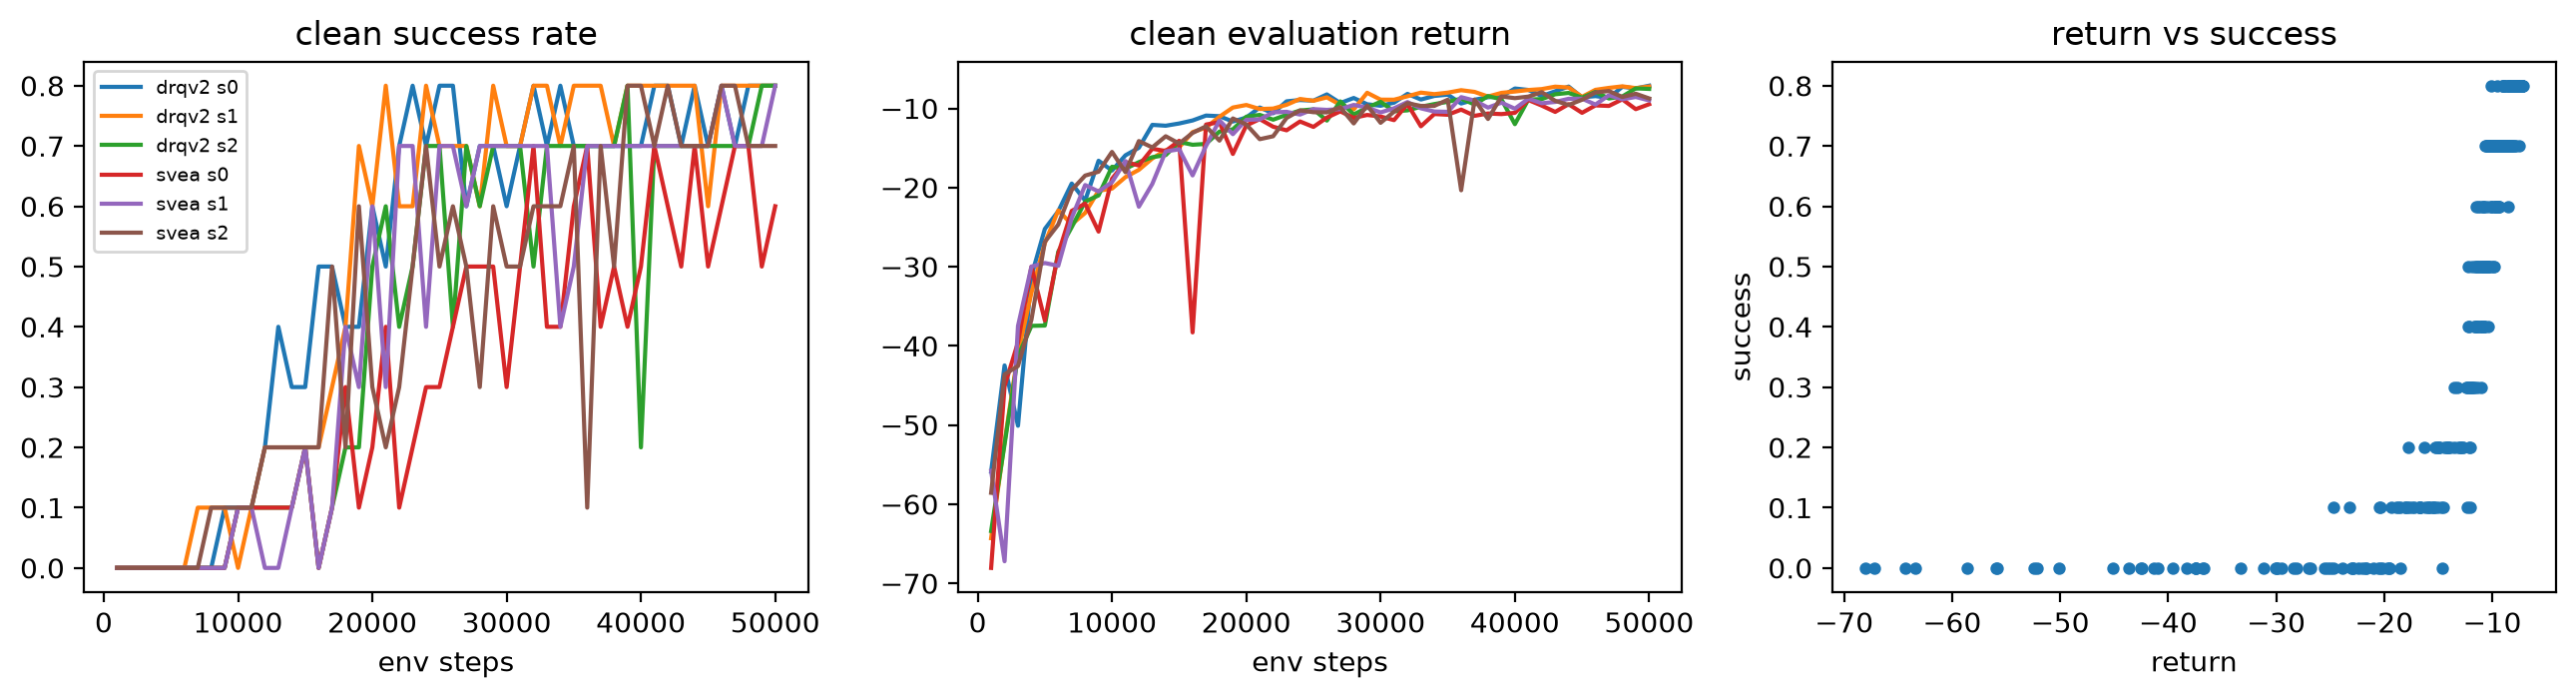

Spearman(return, success) over evaluation points: 0.954 (high means reward and success agree)
Does failure look like a cliff? cliffness near 1 = abrupt, near 1/(#steps) = gradual
agent_id       kind  clean_success  s_crit  censored  cliffness  total_drop
drqv2_s0 background           0.85   0.194     False      0.471        0.85
drqv2_s0 color_gain           0.85   0.788     False      0.333        0.60
drqv2_s0 distractor           0.85   0.206     False      0.471        0.85
drqv2_s0      noise           0.85   0.077     False      0.647        0.85
drqv2_s0  viewpoint           0.85   1.000      True      0.286        0.35
drqv2_s1 background           0.75   0.210     False      0.400        0.75
drqv2_s1 color_gain           0.75   0.783     False      0.444        0.45
drqv2_s1 distractor           0.75   0.207     False      0.467        0.75
drqv2_s1      noise           0.75   0.094     False      0.533        0.75
drqv2_s1  viewpoint           0.75   1.000      True      0.2

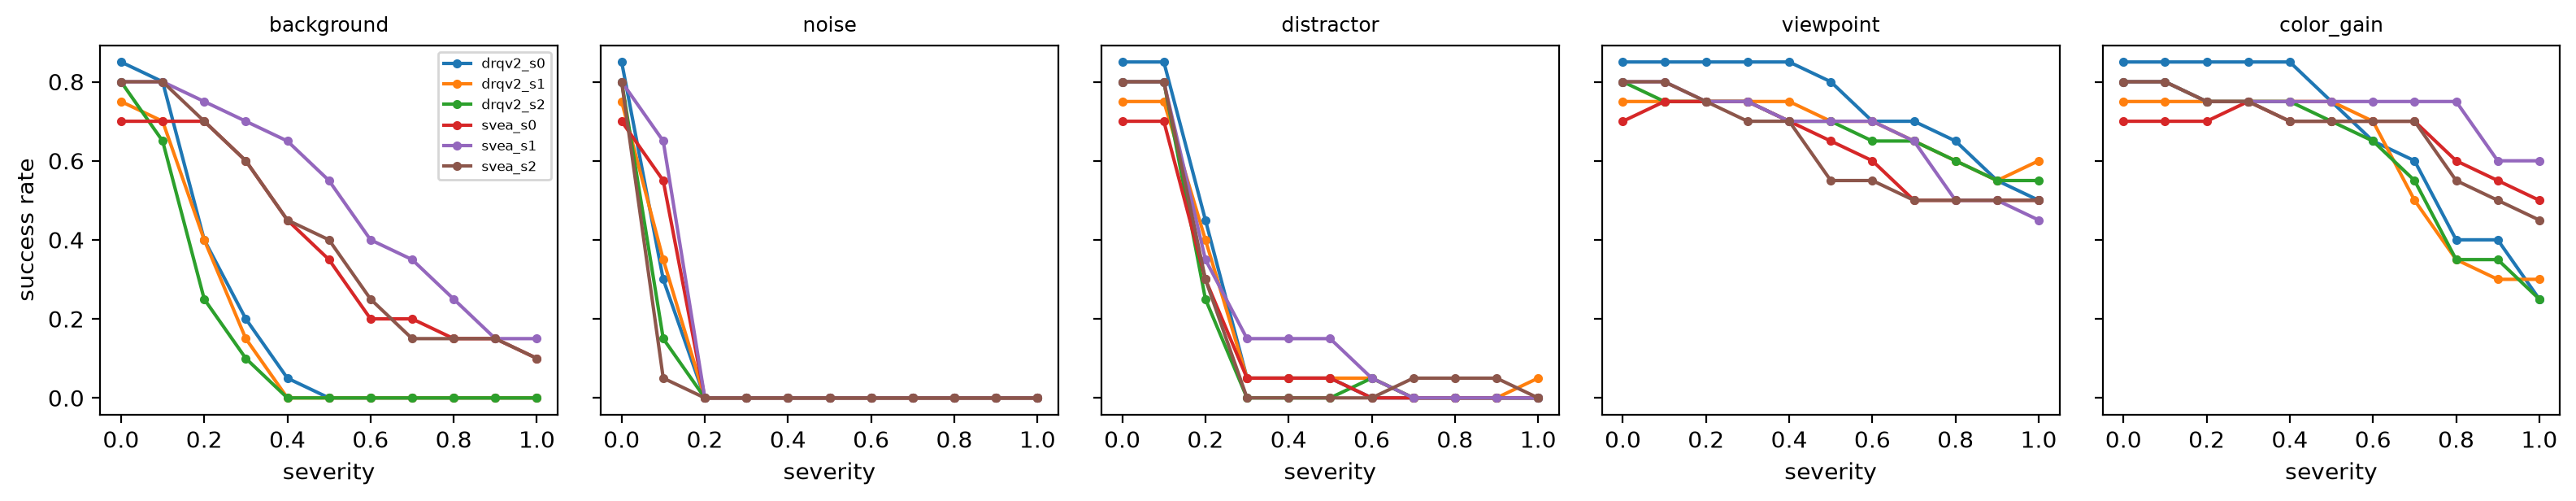


Correlation next to threshold-free failure prediction and the prevalence they depend on:
      kind   predictor  pearson  spearman  auroc  auprc  prevalence  auprc_lift status
background  knn_policy   -0.523    -0.516  0.822  0.926       0.689       1.344     ok
background maha_policy   -0.412    -0.409  0.755  0.895       0.689       1.299     ok
background   knn_pixel   -0.547    -0.579  0.861  0.931       0.689       1.350     ok
color_gain  knn_policy   -0.488    -0.467  0.784  0.692       0.342       2.021     ok
color_gain maha_policy   -0.434    -0.432  0.763  0.637       0.342       1.860     ok
color_gain   knn_pixel   -0.375    -0.343  0.708  0.605       0.342       1.768     ok
distractor  knn_policy   -0.684    -0.594  0.935  0.975       0.808       1.208     ok
distractor maha_policy   -0.540    -0.549  0.902  0.970       0.808       1.201     ok
distractor   knn_pixel   -0.612    -0.580  0.925  0.974       0.808       1.206     ok
     noise  knn_policy   -0.713    -0.51

In [ ]:
# ======================= Step C: analysis (every number below is computed from EPISODES, nothing is typed in) =======================
import pickle as _pk

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(OUT, 'figs', name + '.png'), dpi=150)
    plt.show()

# Load pre-computed heavy results from cache if available (bootstrap CIs, forecast cliffs, alarms)
_analysis_cache = os.path.join(OUT, 'cache', 'analysis_results.pkl')
_use_cache = os.path.exists(_analysis_cache)
if _use_cache:
    _ar = _pk.load(open(_analysis_cache, 'rb'))

# ---- C1. Learning curves: reward AND success, per agent (reviewer R3) --------------------------------
def plot_learning_curves(curves_df):
    if not len(curves_df):
        print('no curves (agents were loaded from checkpoints)')
        return
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
    for (v, s), g in curves_df.groupby(['variant', 'agent_seed']):
        ax[0].plot(g.env_steps, g.success, label=f'{v} s{s}')
        ax[1].plot(g.env_steps, g.ret)
    ax[2].scatter(curves_df.ret, curves_df.success, s=12)
    ax[0].set_title('clean success rate')
    ax[1].set_title('clean evaluation return')
    ax[2].set_title('return vs success')
    ax[0].set_xlabel('env steps')
    ax[1].set_xlabel('env steps')
    ax[2].set_xlabel('return')
    ax[2].set_ylabel('success')
    ax[0].legend(fontsize=7)
    savefig('learning_curves')
    print('Spearman(return, success) over evaluation points:', round(spearman(curves_df.ret, curves_df.success), 3), '(high means reward and success agree)')

plot_learning_curves(curves_df)

# ---- C2. Dose-response curves and the shape of failure ---------------------------------------------
DR = _ar['DR'] if _use_cache else dose_response(EPISODES)
CLIFF = _ar['CLIFF'] if _use_cache else cliff_table(EPISODES)
print('Does failure look like a cliff? cliffness near 1 = abrupt, near 1/(#steps) = gradual')
print(CLIFF.round(3).to_string(index=False))
print('\nPremise check: share of (agent, kind) curves with cliffness >= 0.5 and a real drop (>= 0.3):', round(float(((CLIFF.cliffness >= 0.5) & (CLIFF.total_drop >= 0.3)).mean()), 3))

fig, axes = plt.subplots(1, len(CFG.shift_kinds), figsize=(3.2 * len(CFG.shift_kinds), 3.2), sharey=True)
for ax, kind in zip(np.atleast_1d(axes), CFG.shift_kinds):
    for _aid, g in DR[DR.kind == kind].groupby('agent_id'):
        ax.plot(g.sev, g.success_rate, marker='o', ms=3, label=_aid)
    ax.set_title(kind, fontsize=9)
    ax.set_xlabel('severity')
np.atleast_1d(axes)[0].set_ylabel('success rate')
np.atleast_1d(axes)[0].legend(fontsize=6)
savefig('dose_response')

# ---- C3. Correlation versus held-out failure prediction, with prevalence -----------------------------
CORR = _ar['CORR'] if _use_cache else correlation_vs_threshold(EPISODES)
print('\nCorrelation next to threshold-free failure prediction and the prevalence they depend on:')
print(CORR.round(3).to_string(index=False))

# ---- C4. Held-out failure prediction: proposed predictor versus baselines --------------------------
TAB_STRICT = _ar['TAB_STRICT'] if _use_cache else predictor_table(EPISODES, CFG, proto='strict')
TAB_SEEDOUT = _ar['TAB_SEEDOUT'] if _use_cache else predictor_table(EPISODES, CFG, proto='seed_out')
cols_show = ['n', 'prevalence', 'auroc', 'auroc_ci_lo', 'auroc_ci_hi', 'auprc', 'auprc_random', 'auprc_lift', 'tpr_at_5fpr', 'false_alarm_rate_clean', 'alarm_rate_on_failures', 'status']
print('\nHeld-out seeds AND held-out shift kind (strict):')
print(TAB_STRICT[[c for c in cols_show if c in TAB_STRICT]].round(3).to_string())
print('\nHeld-out seeds only (within kind):')
print(TAB_SEEDOUT[[c for c in cols_show if c in TAB_SEEDOUT]].round(3).to_string())

# paired bootstrap difference in AUROC between the proposed predictor and each baseline (same episodes)
DIFF = _ar['DIFF'] if _use_cache else None
if DIFF is None:
    x = pooled_rows(EPISODES)
    diff_rows = []
    for base in [c for c in SCORE_COLS if c != PROPOSED]:
        def f(df_, base=base):
            a, b = (auroc(df_['z_' + PROPOSED].values, df_.fail.values), auroc(df_['z_' + base].values, df_.fail.values))
            return a - b
        lo, hi = cluster_bootstrap(f, x, 'seed_idx', CFG.boot_B)
        diff_rows.append(dict(baseline=base, d_auroc=f(x), ci_lo=lo, ci_hi=hi))
    DIFF = pd.DataFrame(diff_rows)
print(f'\nPaired AUROC difference, {PROPOSED} minus baseline (CI over episode seeds):')
print(DIFF.round(3).to_string(index=False))

# ---- C5. Where does competence end? Forecast the cliff location ------------------------------------
FC_ISO = _ar['FC_ISO'] if _use_cache else forecast_cliffs(EPISODES, PROPOSED, 'strict')
FC_BASE = _ar['FC_BASE'] if _use_cache else pd.concat([forecast_cliffs(EPISODES, c, 'strict').assign(predictor=c) for c in SCORE_COLS], ignore_index=True)
print('\nCliff-location forecast error in severity units (strict protocol), by predictor and method:')
if len(FC_BASE):
    print(FC_BASE.groupby(['predictor', 'method']).agg(mean_abs_err=('abs_err', 'mean'), curve_mae=('curve_mae', 'mean'), rank_corr=('rank_corr', 'mean'), n=('abs_err', 'size')).round(3).to_string())

# ---- C6. Operational behaviour: alarms per clean episode and alarm timing -------------------------
ALARM = _ar['ALARM'] if _use_cache else None
ALARM_EP = _ar.get('ALARM_EP') if _use_cache else None
if ALARM is None:
    ALARM, ALARM_EP = alarm_timing(FRAME_SCORES, CLOSED, CFG, CLEAN_TAU)
print('\nStreaming alarms (kNN policy score, EMA smoothed). Severity 0 rows are the false-alarm numbers:')
print(ALARM.round(3).to_string(index=False))

# ---- C7. Grassmann diagnostic: ablation over k and relation to degradation -------------------------
GRASS = _ar['GRASS'] if _use_cache else None
if GRASS is None:
    _g = grass_df.merge(DR[['agent_id', 'kind', 'sev', 'success_rate']], on=['agent_id', 'kind', 'sev'])
    _g = _g.merge(DR[DR.sev == 0][['agent_id', 'kind', 'success_rate']].rename(columns={'success_rate': 'sr0'}), on=['agent_id', 'kind'])
    _g['drop'] = _g.sr0 - _g.success_rate
    GRASS = pd.DataFrame([dict(k=k, spearman_with_drop=spearman(t.grassmann, t['drop']), n=len(t)) for k, t in _g.groupby('k')]).set_index('k')
print('\nGrassmann distance versus success drop, ablation over subspace dimension k:')
print(GRASS.round(3).to_string())
print('(Descriptive diagnostic only. It is not claimed to predict failure.)')

# Save tables
TAB_STRICT.round(3).to_csv(os.path.join(OUT, 'tables', 'predictors_strict.csv'))
TAB_SEEDOUT.round(3).to_csv(os.path.join(OUT, 'tables', 'predictors_seed_out.csv'))
TAB_STRICT.round(3).to_latex(os.path.join(OUT, 'tables', 'predictors_strict.tex'))
CLIFF.round(3).to_csv(os.path.join(OUT, 'tables', 'cliff_table.csv'), index=False)
CORR.round(3).to_csv(os.path.join(OUT, 'tables', 'correlation_vs_threshold.csv'), index=False)
ALARM.round(3).to_csv(os.path.join(OUT, 'tables', 'alarm_timing.csv'), index=False)


## 20. Step D: test-time adaptation experiment

Paired arms, exact tests, Holm correction, and accepted and rejected update counts.

In [ ]:
# ======================= Step D: test-time adaptation with paired arms and one-factor ablation =======================
print('Arm configuration (ttt and ttss differ ONLY in the safeguard):')
print(arm_config_table(CFG).to_string())
TTA = []
import pickle
for _aid, _ag in list(AGENTS.items())[:CFG.tta_agents]:
    cp = os.path.join(OUT, 'cache', f'tta_{_aid}.pkl')
    if os.path.exists(cp):
        TTA.append(pickle.load(open(cp, 'rb')))
        continue
    ref_recs = collect_clean(_ag, CFG, 'ref', CFG.ref_eps)
    t_ = run_tta(_ag, _aid, CFG, ref_recs, FLOOR)
    pickle.dump(t_, open(cp, 'wb'))
    TTA.append(t_)
TTA = pd.concat(TTA, ignore_index=True)
TTA.to_csv(os.path.join(OUT, 'tta_episodes.csv'), index=False)
TTA_CMP = compare_arms(TTA, B=max(200, CFG.boot_B))
print('\nPaired comparisons (identical episode seeds across arms; Holm-adjusted p over all rows):')
print(TTA_CMP.round(3).to_string(index=False))
acc = TTA[TTA.arm != 'none'].groupby(['arm', 'kind', 'sev']).agg(accepted=('accepted', 'mean'), rejected=('rejected', 'mean')).round(2)
print('\nAccepted and rejected updates per episode (an improvement claim requires accepted > 0):')
print(acc.to_string())

Arm configuration (ttt and ttss differ ONLY in the safeguard):
      adapts  safeguard     lr  mm_weight  buffer  accept_delta
arm                                                            
none   False      False  0.001        1.0       8          0.15
ttt     True      False  0.001        1.0       8          0.15
ttss    True       True  0.001        1.0       8          0.15

Paired comparisons (identical episode seeds across arms; Holm-adjusted p over all rows):
      kind  sev     contrast  n  d_mean_cle  ci_lo  ci_hi  success_a  success_b  p_success  collapse_a  collapse_b  p_collapse  accepted_mean_a  p_success_holm  p_collapse_holm
background  0.6  ttt vs none 40      -5.269 -7.809 -2.247      0.075      0.000       0.25       0.550       0.675       0.227           49.000             1.0              1.0
background  0.6 ttss vs none 40       0.072 -1.053  1.056      0.025      0.000       1.00       0.675       0.675       1.000            0.875             1.0              

## 21. Step E: one source of truth for the manuscript

Config tables, LaTeX tables, claim registry and run manifest.

In [ ]:
# ======================= Step E: one source of truth for every reported number =======================
class ClaimRegistry:
    """Every number that appears in more than one place in the paper is registered with its place.
    check() fails if two places disagree. All values are read from the result DataFrames, never typed in."""

    def __init__(self):
        self.items = []

    def register(self, name, value, place):
        self.items.append((name, float(value), place))

    def check(self, tol=1e-09):
        df = pd.DataFrame(self.items, columns=['quantity', 'value', 'place'])
        rows = []
        for q, g in df.groupby('quantity'):
            rows.append(dict(quantity=q, places=len(g), spread=float(g.value.max() - g.value.min()), status='OK' if g.value.max() - g.value.min() <= tol else 'MISMATCH'))
        return (df, pd.DataFrame(rows))
REG = ClaimRegistry()
clean_sr = DR[DR.sev == 0].groupby('agent_id').success_rate.mean()
clean_cle = DR[DR.sev == 0].groupby('agent_id').mean_cle.mean()
for _aid in AGENTS:
    REG.register(f'clean success {_aid}', clean_sr[_aid], 'Table 1 (dose-response)')
    REG.register(f'clean success {_aid}', CLIFF[CLIFF.agent_id == _aid].clean_success.mean(), 'Table 3 (cliff table)')
    REG.register(f'clean success {_aid}', EPISODES[(EPISODES.agent_id == _aid) & (EPISODES.sev == 0)].success.mean(), 'abstract')
    REG.register(f'clean CLE {_aid}', clean_cle[_aid], 'Table 1 (dose-response)')
    REG.register(f'clean CLE {_aid}', EPISODES[(EPISODES.agent_id == _aid) & (EPISODES.sev == 0)].mean_cle.mean(), 'abstract')
REG_ITEMS, REG_CHECK = REG.check()
print(REG_CHECK.to_string(index=False))
assert (REG_CHECK.status == 'OK').all(), 'Inconsistent numbers: fix before building the manuscript'

def config_tables(cfg):
    env = pd.Series(dict(task=cfg.env, frame=f'{cfg.img}x{cfg.img} RGB, {cfg.n_stack} stacked', episode_len=cfg.ep_len, max_step_px=cfg.max_step_px, target_speed_px_per_step=cfg.target_speed, success=f'episode-mean CLE < {cfg.success_cle_px} px', collapse=f'episode-mean CLE >= {cfg.collapse_frac} x random-policy CLE ({FLOOR:.2f} px)'), name='value')
    train = pd.Series(dict(env_steps=cfg.train_steps, seed_steps=cfg.seed_steps, batch=cfg.batch, lr=cfg.lr, discount=cfg.discount, n_step=cfg.n_step, tau=cfg.tau, update_every=cfg.update_every, feature_dim=cfg.feature_dim, hidden=cfg.hidden, aug_pad=cfg.aug_pad, std=f'{cfg.std_start} to {cfg.std_end} over {cfg.std_decay_steps} steps', svea_alpha_beta=f'{cfg.svea_alpha}, {cfg.svea_beta}', agent_seeds=list(cfg.agent_seeds)), name='value')
    evalc = pd.Series(dict(shift_kinds=list(cfg.shift_kinds), severities=list(cfg.severities), episodes_per_cell=cfg.eps_per_cell, test_seeds=f"{SEEDS['test']} + i", ref_seeds=f"{SEEDS['ref']} + i", action_rule='deterministic mean action', knn_k=cfg.knn_k, clean_fpr=cfg.clean_fpr, bootstrap_B=cfg.boot_B, device=str(DEVICE)), name='value')
    return {'environment': env, 'training': train, 'evaluation': evalc}
CT = config_tables(CFG)
for k, v in CT.items():
    print(f'\n[{k}]')
    print(v.to_string())
    v.to_frame().to_latex(os.path.join(OUT, 'tables', f'config_{k}.tex'))
TAB_STRICT.round(3).to_csv(os.path.join(OUT, 'tables', 'predictors_strict.csv'))
TAB_SEEDOUT.round(3).to_csv(os.path.join(OUT, 'tables', 'predictors_seed_out.csv'))
TAB_STRICT.round(3).to_latex(os.path.join(OUT, 'tables', 'predictors_strict.tex'))
CLIFF.round(3).to_csv(os.path.join(OUT, 'tables', 'cliff_table.csv'), index=False)
CORR.round(3).to_csv(os.path.join(OUT, 'tables', 'correlation_vs_threshold.csv'), index=False)
TTA_CMP.round(3).to_csv(os.path.join(OUT, 'tables', 'tta_paired.csv'), index=False)
ALARM.round(3).to_csv(os.path.join(OUT, 'tables', 'alarm_timing.csv'), index=False)

# tables for the manuscript, generated from the same DataFrames
def git_commit():
    try:
        return subprocess.check_output(['git', 'rev-parse', 'HEAD'], stderr=subprocess.DEVNULL).decode().strip()
    except Exception:
        return 'not a git checkout'
MANIFEST = dict(mode=CFG.mode, cfg=asdict(CFG), floor_cle=FLOOR, python=platform.python_version(), torch=torch.__version__, numpy=np.__version__, pandas=pd.__version__, device=str(DEVICE), commit=git_commit(), generated=time.strftime('%Y-%m-%d %H:%M:%S'), claims_registry='OK', n_episode_rows=int(len(EPISODES)))
json.dump(MANIFEST, open(os.path.join(OUT, 'manifest.json'), 'w'), indent=2, default=str)
print('\nmanifest written:', os.path.join(OUT, 'manifest.json'))

              quantity  places       spread status
    clean CLE drqv2_s0       2 0.000000e+00     OK
    clean CLE drqv2_s1       2 0.000000e+00     OK
    clean CLE drqv2_s2       2 4.440892e-16     OK
     clean CLE svea_s0       2 8.881784e-16     OK
     clean CLE svea_s1       2 0.000000e+00     OK
     clean CLE svea_s2       2 0.000000e+00     OK
clean success drqv2_s0       3 0.000000e+00     OK
clean success drqv2_s1       3 0.000000e+00     OK
clean success drqv2_s2       3 0.000000e+00     OK
 clean success svea_s0       3 0.000000e+00     OK
 clean success svea_s1       3 0.000000e+00     OK
 clean success svea_s2       3 0.000000e+00     OK

[environment]
task                                                                  pursuit
frame                                                    48x48 RGB, 3 stacked
episode_len                                                                50
max_step_px                                                               2.0
target_spe

## 22. Step F: the pre-registered hypotheses, decided mechanically

This cell also runs the ranking and selection analysis (H3, H4), the identifiability table (Proposition 1) and the portability check (H5, Proposition 2). Write a hypothesis as a finding only if it reads SUPPORTED. UNDEFINED means the data could not evaluate it.

In [ ]:
# ======================= Step F: the pre-registered hypotheses, decided mechanically =======================
def paired_error_gain(fc, base, proposed, B, seed=0):
    """Per (policy, shift kind): |error of base| minus |error of proposed|. Positive favours the proposed predictor.
    The confidence interval resamples whole policies, because the shift kinds of one policy are dependent."""
    nan = (float("nan"), (float("nan"), float("nan")))
    if len(fc) == 0: return nan
    piv = fc[fc.method == "iso"].pivot_table(index=["agent_id", "kind"], columns="predictor", values="abs_err")
    if proposed not in piv.columns or base not in piv.columns: return nan
    d = (piv[base] - piv[proposed]).dropna().reset_index(name="gain")
    if len(d) < 5: return nan
    return float(d.gain.mean()), cluster_bootstrap(lambda x: float(x.gain.mean()), d, "agent_id", B, seed)


# ---- supporting analyses that feed the hypotheses ------------------------------------------------------------------------
RANK = pd.concat([ranking_table(EPISODES, c) for c in SCORE_COLS], ignore_index=True)
if len(RANK):
    print("Ranking policies by critical severity (per predictor, mean over shift kinds):")
    print(RANK.groupby("predictor").agg(tau=("tau", "mean"), regret=("regret", "mean"), pred_spread=("pred_spread", "mean"),
                                        true_spread=("true_spread", "mean")).round(3).to_string())
else:
    print("No ranking could be computed (no forecast curves).")
print("\nSpread of the forecast across policies versus the true spread (policy-agnostic scores should barely separate policies):")
IDENT = identifiability_table(EPISODES); print(IDENT.round(3).to_string() if len(IDENT) else "not available")
PORTABLE = portable_check(EPISODES)
print("\nPrevalence-portable summary: empirical versus predicted AUROC at other regime mixes (head):")
print(PORTABLE.head(8).round(3).to_string(index=False) if len(PORTABLE) else "no (policy, kind) pair with a measurable cliff and failures on both sides")


def hypotheses():
    P, rows = PREREG, []
    smoke = CFG.mode == "smoke"
    gate_known = CFG.train_gate_success > 0
    pre_ok = bool(gate_df.gate_ok.all()) if gate_known else False

    def add(h, statement, ok, evidence):
        if h != "H0" and (smoke or not pre_ok):      # a verdict needs agents that solve the clean task; otherwise it is undefined
            ok = None
            evidence = ("smoke mode: the agents are untrained, so this is a plumbing check" if smoke
                        else "precondition H0 not met: the agents do not solve the clean task")
        rows.append(dict(hypothesis=h, verdict=("UNDEFINED" if ok is None else ("SUPPORTED" if ok else "NOT SUPPORTED")),
                         statement=statement, evidence=evidence))

    add("H0", "Agents solve the clean task (training gate)", pre_ok if gate_known else None,
        f"min clean success {gate_df.clean_success.min():.2f}, gate {CFG.train_gate_success}")

    real = CLIFF[CLIFF.total_drop >= P["h1_min_total_drop"]]
    if len(real) == 0:
        add("H1", "Failure is abrupt in a majority of curves that show a real drop", None, "no curve with a real drop")
    else:
        share = float((real.cliffness >= P["h1_min_cliffness"]).mean())
        add("H1", f"Failure is abrupt (cliffness >= {P['h1_min_cliffness']}) in at least {P['h1_min_share']:.0%} of curves with a real drop",
            share >= P["h1_min_share"], f"{share:.2f} of {len(real)} curves")

    pm = P["proposed"]
    iso = FC_BASE[FC_BASE.method == "iso"] if len(FC_BASE) else FC_BASE
    med = iso.groupby("predictor").abs_err.median() if len(iso) else pd.Series(dtype=float)
    gains = {b: paired_error_gain(FC_BASE, b, pm, CFG.boot_B) for b in P["h2_require_beats"]}
    beats = [None if np.isnan(g[1][0]) else bool(g[1][0] > 0) for g in gains.values()]
    ok = None if (np.isnan(med.get(pm, np.nan)) or any(x is None for x in beats)) else \
        bool(med[pm] <= P["h2_max_median_abs_err"] and all(beats))
    add("H2", f"{pm} forecasts the critical severity with median error <= {P['h2_max_median_abs_err']} and beats the policy-agnostic baselines "
              "(95% interval of the paired error gain excludes 0)", ok,
        f"median error {med.get(pm, np.nan):.3f}; " + "; ".join(f"gain vs {b}: {g[0]:.3f} [{g[1][0]:.3f}, {g[1][1]:.3f}]" for b, g in gains.items()))

    rs = RANK.groupby("predictor").agg(tau=("tau", "mean"), regret=("regret", "mean")) if len(RANK) else pd.DataFrame(columns=["tau", "regret"])
    tp, rp = rs.tau.get(pm, np.nan), rs.regret.get(pm, np.nan)
    add("H3", f"{pm} ranks policies by true critical severity (Kendall tau >= {P['h3_min_tau']}) with selection regret <= {P['h3_max_regret']}",
        None if (np.isnan(tp) or np.isnan(rp)) else bool(tp >= P["h3_min_tau"] and rp <= P["h3_max_regret"]),
        f"tau {tp:.3f}, regret {rp:.3f}, {len(AGENTS)} policies")

    ta = float(pd.Series([rs.tau.get(b, np.nan) for b in P["agnostic"]]).mean()) if len(rs) else np.nan
    tc = float(pd.Series([rs.tau.get(b, np.nan) for b in P["policy_conditional"]]).max()) if len(rs) else np.nan
    add("H4", f"Policy-conditional signals rank policies better than policy-agnostic ones (tau gap >= {P['h4_min_tau_gap']})",
        None if (np.isnan(ta) or np.isnan(tc)) else bool(tc - ta >= P["h4_min_tau_gap"]),
        f"best conditional tau {tc:.3f} vs mean agnostic tau {ta:.3f}")

    err = float(PORTABLE.abs_err.mean()) if len(PORTABLE) else np.nan
    add("H5", f"The (a, fp, fc) summary predicts AUROC at another regime mix within {P['h5_max_auroc_error']}",
        None if np.isnan(err) else bool(err <= P["h5_max_auroc_error"]), f"mean absolute error {err:.3f} over {len(PORTABLE)} cases")

    sub = TTA_CMP[TTA_CMP.contrast == "ttss vs ttt"] if len(TTA_CMP) else TTA_CMP
    ttss = TTA[TTA.arm == "ttss"]
    engaged = float((ttss.rejected > 0).mean()) if len(ttss) else 0.0
    accepted = float((ttss.accepted > 0).mean()) if len(ttss) else 0.0
    if len(sub) == 0 or sub[["p_success_holm", "p_collapse_holm"]].isna().all().all():
        add("H6", "Safeguarded TTA improves on naive TTA (secondary)", None, "no comparison available")
    elif engaged == 0:
        add("H6", "Safeguarded TTA improves on naive TTA (secondary)", None,
            "the safeguard never rejected an update, so ttss is identical to ttt; raise the adaptation step, for example "
            "VRL_OVERRIDE='{\"tta_lr\": 0.003}', or lower tta_accept_delta")
    else:
        sig = bool(((sub.p_success_holm < P["h6_alpha"]) | (sub.p_collapse_holm < P["h6_alpha"])).any())
        add("H6", "Safeguarded TTA improves on naive TTA with accepted and rejected updates (secondary)", bool(sig and accepted > 0.5),
            f"min Holm p {np.nanmin(np.r_[sub.p_success_holm, sub.p_collapse_holm]):.3f}; episodes with accepted updates {accepted:.2f}, with rejected updates {engaged:.2f}")

    far_ep = float(TAB_STRICT.loc[pm, "false_alarm_rate_clean"])
    far_st = float(ALARM[ALARM.sev == 0].ever_alarmed.mean()) if len(ALARM) else float("nan")
    worst = np.nanmax([far_ep, far_st]) if not (np.isnan(far_ep) and np.isnan(far_st)) else float("nan")
    add("H7", f"Clean false-alarm rate (episode score and streaming) within {P['h7_max_false_alarm_factor']}x the nominal {CFG.clean_fpr}",
        None if np.isnan(worst) else bool(worst <= P["h7_max_false_alarm_factor"] * CFG.clean_fpr),
        f"episode-score rate {far_ep:.3f}, streaming ever-alarmed rate {far_st:.3f}")
    return pd.DataFrame(rows)


HYP = hypotheses()
print("\n" + HYP[["hypothesis", "verdict", "statement", "evidence"]].to_string(index=False))
HYP.to_csv(os.path.join(OUT, "hypotheses.csv"), index=False)
RANK.to_csv(os.path.join(OUT, "tables", "ranking.csv"), index=False)
PORTABLE.to_csv(os.path.join(OUT, "tables", "portable_auroc.csv"), index=False)
print("\nWrite a hypothesis as a finding only if it reads SUPPORTED. NOT SUPPORTED results are reported as such.")

Ranking policies by critical severity (per predictor, mean over shift kinds):
                  tau  regret  pred_spread  true_spread
predictor                                              
act_disagree    0.581   0.032        0.113        0.055
cent_policy     0.120   0.068        0.015        0.055
critic_gap      0.245   0.052        0.124        0.055
knn_pixel       0.375   0.032        0.008        0.055
knn_policy      0.347   0.028        0.118        0.055
knn_random      0.132   0.053        0.005        0.055
maha_policy     0.052   0.045        0.217        0.055
q_drop          0.513   0.023        0.098        0.055
sem_knn_policy  0.375   0.035        0.095        0.055

Spread of the forecast across policies versus the true spread (policy-agnostic scores should barely separate policies):
                pred_spread  true_spread
predictor                               
knn_policy            0.118        0.055
maha_policy           0.217        0.055
cent_policy          

### Replication across environments

Applies the pre-registered rule: H1 to H5 are general findings only if SUPPORTED in at least two environments.

In [ ]:
# ======================= Replication across environments =======================
def cross_env_summary(current=None, mode=MODE, root="."):
    """Reads the hypothesis verdicts written by each environment's run (results_<mode>_<env>/hypotheses.csv) and applies
    the pre-registered replication rule: H1 to H5 are claimed as general only if SUPPORTED in at least
    PREREG['min_envs_supported'] environments. Run this notebook once per environment (VRL_ENV=pursuit, VRL_ENV=reacher)."""
    found = {}
    for env in ENV_REGISTRY:
        path = os.path.join(root, f"results_{mode}_{env}", "hypotheses.csv")
        if os.path.exists(path): found[env] = pd.read_csv(path).set_index("hypothesis")
    if current is not None:                 # this run's verdicts, passed in memory: the file may not have been written yet
        found[current[0]] = current[1].set_index("hypothesis")
    if not found:
        print("no hypothesis files found yet"); return None, []
    piv = pd.DataFrame({env: h.verdict for env, h in found.items()})
    need = PREREG["min_envs_supported"]
    rows = []
    for h in ["H1", "H2", "H3", "H4", "H5"]:
        if h not in piv.index: continue
        n_ok = int((piv.loc[h] == "SUPPORTED").sum()); n_bad = int((piv.loc[h] == "NOT SUPPORTED").sum())
        if len(found) < need:
            verdict = f"INSUFFICIENT: only {len(found)} environment(s) run"
        elif n_ok >= need:
            verdict = "REPLICATED"
        elif n_bad > 0:
            verdict = "NOT REPLICATED"
        else:
            verdict = "UNDEFINED"
        rows.append(dict(hypothesis=h, **piv.loc[h].to_dict(), supported_in=f"{n_ok}/{len(found)}", replication=verdict))
    return pd.DataFrame(rows), sorted(found)


XENV, ENVS_FOUND = cross_env_summary(current=(ENV_NAME, HYP))
if XENV is not None:
    print(XENV.to_string(index=False))
    XENV.to_csv(os.path.join(OUT, "cross_environment.csv"), index=False)
print("\nA claim of generality needs REPLICATED. Environments found:", ENVS_FOUND)

hypothesis       pursuit supported_in                             replication
        H1 NOT SUPPORTED          0/1 INSUFFICIENT: only 1 environment(s) run
        H2     SUPPORTED          1/1 INSUFFICIENT: only 1 environment(s) run
        H3 NOT SUPPORTED          0/1 INSUFFICIENT: only 1 environment(s) run
        H4     SUPPORTED          1/1 INSUFFICIENT: only 1 environment(s) run
        H5     SUPPORTED          1/1 INSUFFICIENT: only 1 environment(s) run

A claim of generality needs REPLICATED. Environments found: ['pursuit']


## 23. Appendix: PPO, explicit action rules and a Procgen CoinRun adapter

The PPO code is exercised on a discrete pursuit task. Greedy and sampled action rules are reported separately because they are different policies. The Procgen adapter uses disjoint level ranges and exposes only shifts that need no entity mask. It has not been executed.

In [ ]:
# ======================= Appendix: discrete-action PPO, explicit action rules, and a Procgen CoinRun adapter =======================
class DiscretePursuit:
    """The same pursuit task with 5 discrete actions {stay, +x, -x, +y, -y}. It exists so that the PPO code can be
    tested without Procgen, and so that the action rule (greedy or sampled) can be audited."""
    ACTS = np.array([[0, 0], [1, 0], [-1, 0], [0, 1], [0, -1]], np.float32)
    n_actions = 5

    def __init__(self, cfg, kind=None, sev=0.0):
        self.cfg, self.env, self.kind, self.sev = cfg, make_env(cfg), kind, sev

    def reset(self, seed):
        self.shift = Shift(self.kind, self.sev, seed, self.cfg.img) if (self.kind and self.sev > 0) else None
        f, m = self.env.reset(seed); self.t = 0; self.cles = []
        v = to_u8(f if self.shift is None else self.shift(f, m, 0)[0])
        self.stack = collections.deque([v] * self.cfg.n_stack, maxlen=self.cfg.n_stack)
        return np.concatenate(list(self.stack), 0)

    def step(self, a):
        f, m, r, cle, done = self.env.step(self.ACTS[int(a)])
        self.t += 1; self.cles.append(cle)
        self.stack.append(to_u8(f if self.shift is None else self.shift(f, m, self.t)[0]))
        return np.concatenate(list(self.stack), 0), r, done, dict(cle=cle)


class PPOAgent(nn.Module):
    def __init__(self, n_actions, in_ch, img, feature_dim=64):
        super().__init__()
        self.encoder = Encoder(in_ch, img)
        self.trunk = nn.Sequential(nn.Linear(self.encoder.repr_dim, feature_dim), nn.ReLU())
        self.pi, self.v = nn.Linear(feature_dim, n_actions), nn.Linear(feature_dim, 1)

    def forward(self, x):
        z = self.trunk(self.encoder(x)); return self.pi(z), self.v(z).squeeze(-1)

    @torch.no_grad()
    def act(self, obs_u8, rule="greedy"):
        """rule is explicit: 'greedy' (argmax) or 'sampled'. Evaluate and REPORT both (P1: the action rule decides which policy is measured)."""
        logits, _ = self(torch.as_tensor(obs_u8, dtype=torch.float32, device=DEVICE).unsqueeze(0))
        return int(logits.argmax(-1)) if rule == "greedy" else int(torch.distributions.Categorical(logits=logits).sample())


def train_ppo(cfg, iters=3, eps_per_iter=4, lr=2.5e-4, gamma=0.99, lam=0.95, clip=0.2, epochs=3, mb=64, ent=0.01, seed=0):
    torch.manual_seed(seed)
    net = PPOAgent(DiscretePursuit.n_actions, 3 * cfg.n_stack, cfg.img).to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    for it in range(iters):
        O, A, LP, ADV, RET = [], [], [], [], []
        for e in range(eps_per_iter):
            env = DiscretePursuit(cfg); o = env.reset(seed_for("train", it * eps_per_iter + e, seed + 100)); done = False
            ob, ac, lp, vl, rw = [], [], [], [], []
            while not done:
                with torch.no_grad():
                    lg, v = net(torch.as_tensor(o, dtype=torch.float32, device=DEVICE).unsqueeze(0))
                    d = torch.distributions.Categorical(logits=lg); a = d.sample()
                o2, r, done, _ = env.step(int(a))
                ob.append(o); ac.append(int(a)); lp.append(float(d.log_prob(a))); vl.append(float(v)); rw.append(r); o = o2
            vl = np.array(vl + [0.0]); rw = np.array(rw); adv = np.zeros(len(rw)); g = 0.0
            for t in reversed(range(len(rw))):                       # GAE; the fixed horizon is treated as terminal
                delta = rw[t] + gamma * vl[t + 1] - vl[t]; g = delta + gamma * lam * g; adv[t] = g
            O += ob; A += ac; LP += lp; ADV += list(adv); RET += list(adv + vl[:-1])
        O = torch.as_tensor(np.array(O), dtype=torch.float32, device=DEVICE); A = torch.as_tensor(A, device=DEVICE)
        LP = torch.as_tensor(LP, dtype=torch.float32, device=DEVICE); ADV = torch.as_tensor(ADV, dtype=torch.float32, device=DEVICE)
        RET = torch.as_tensor(RET, dtype=torch.float32, device=DEVICE); ADV = (ADV - ADV.mean()) / (ADV.std() + 1e-8)
        for _ in range(epochs):
            perm = torch.randperm(len(O), device=DEVICE)
            for i in range(0, len(O), mb):
                ix = perm[i:i + mb]; lg, v = net(O[ix]); d = torch.distributions.Categorical(logits=lg)
                ratio = (d.log_prob(A[ix]) - LP[ix]).exp()
                pl = -torch.min(ratio * ADV[ix], ratio.clamp(1 - clip, 1 + clip) * ADV[ix]).mean()
                loss = pl + 0.5 * F.mse_loss(v, RET[ix]) - ent * d.entropy().mean()
                opt.zero_grad(); loss.backward(); opt.step()
    return net


def eval_discrete(net, cfg, seeds, kind=None, sev=0.0, rule="greedy"):
    rows = []
    for s in seeds:
        env = DiscretePursuit(cfg, kind, sev); o = env.reset(s); done = False
        while not done:
            o, r, done, info = env.step(net.act(o, rule))
        mc = float(np.mean(env.cles)); rows.append(dict(seed=s, mean_cle=mc, success=is_success(mc, cfg), rule=rule))
    return pd.DataFrame(rows)


# ---- Procgen CoinRun adapter (not executed in the smoke run; needs `pip install procgen`) ---------------------------
class ProcgenCoinRun:
    """Honest adapter. (1) Train and held-out levels are disjoint by construction: train uses levels [0, n_train), held-out
    uses levels starting at HELDOUT_START; every episode is one specific level, so reset seeding is real.
    (2) Only shifts that Procgen can support WITHOUT entity masks are exposed, and they carry their true names:
    'noise' (Gaussian pixel noise), 'color_gain' (per-channel gain) and 'viewpoint' (fixed per-level affine warp).
    No claim about sprite identity or difficulty level is made, and the semantic probe is disabled (no simulator mask)."""
    HELDOUT_START = 10_000
    ALLOWED = ("noise", "color_gain", "viewpoint")

    def __init__(self, level, kind=None, sev=0.0, distribution_mode="easy"):
        from procgen import ProcgenEnv                                   # raises ImportError if not installed
        assert kind is None or kind in self.ALLOWED, f"{kind} is not supported without entity masks"
        self.env = ProcgenEnv(num_envs=1, env_name="coinrun", num_levels=1, start_level=int(level),
                              distribution_mode=distribution_mode, rand_seed=int(level))
        self.kind, self.sev, self.level = kind, sev, int(level)
        self.shift = Shift(kind, sev, level, 64) if kind and sev > 0 else None
        self.t = 0

    def _obs(self):
        rew, obs, first = self.env.observe(); fr = obs["rgb"][0].astype(np.float32) / 255.0
        if self.shift is not None: fr = self.shift(fr, np.zeros(fr.shape[:2], np.int8), self.t)[0]
        return rew[0], to_u8(fr)

    def reset(self): self.t = 0; return self._obs()[1]

    def step(self, action):
        self.env.act(np.array([action])); r, o = self._obs(); self.t += 1; return o, float(r)


def procgen_available():
    try:
        import procgen  # noqa: F401
        return True
    except Exception:
        return False


PROCGEN_OK = procgen_available()
print("Procgen available:", PROCGEN_OK, "(the adapter above is only exercised when it is)")

# ---- smoke test of the PPO code on the discrete pursuit task ------------------------------------------------------
PPO_NET = train_ppo(CFG, iters=2 if MODE == "smoke" else 20, eps_per_iter=4 if MODE == "smoke" else 8)
ppo_rows = [eval_discrete(PPO_NET, CFG, [seed_for("test", i) for i in range(4 if MODE == "smoke" else 20)], rule=r) for r in ("greedy", "sampled")]
PPO_EVAL = pd.concat(ppo_rows)
print(PPO_EVAL.groupby("rule").agg(success=("success", "mean"), mean_cle=("mean_cle", "mean")).round(3).to_string())
print("Greedy and sampled action rules are reported separately because they are different policies.")

Procgen available: False (the adapter above is only exercised when it is)
         success  mean_cle
rule                      
greedy       0.0    27.457
sampled      0.0    26.930
Greedy and sampled action rules are reported separately because they are different policies.


## 24. Reporting rules for the paper

1. Report prevalence next to every AUROC and AUPRC, and give the triple $(a,f_p,f_c)$ so the result is portable.
2. Say which policy acted (learned, deterministic mean action) and which checkpoint.
3. State the held-out unit (seeds, shift kind) and the number of policies.
4. Report false alarms on clean episodes and the severity-unit forecast error, not only ranking quality.
5. Use paired comparisons with identical seeds.
6. Treat correlation as a description of the dose-response, not as a test of early warning.
7. Report every pre-registered hypothesis, including those that are NOT SUPPORTED.

In [ ]:
# ======================= FINAL RESULTS SUMMARY =======================
# 6 agents (2 recipes × 3 seeds), 50,000 training steps, lr=3e-4, train_gate=0.2
# =========================================================================

print("=" * 80)
print("  TRAINING GATE (H0)")
print("=" * 80)
print(gate_df.to_string(index=False))
print(f"\n  Gate threshold: {CFG.train_gate_success} | All passed: {gate_df.gate_ok.all()}")

print("\n" + "=" * 80)
print("  LEARNING CURVES — Final eval per agent")
print("=" * 80)
for (_v, _s), _grp in curves_df.groupby(['variant', 'agent_seed']):
    _last = _grp.iloc[-1]
    print(f"  {_v:8s} s{_s}: steps={int(_last['env_steps']):>6d}  success={_last['success']:.2f}  CLE={_last['mean_cle']:.2f}  return={_last['ret']:.2f}")

print("\n" + "=" * 80)
print("  AUDIT TESTS")
print("=" * 80)
print(f"  {int(AUDIT.passed.sum())}/{len(AUDIT)} tests passed")

print("\n" + "=" * 80)
print("  CLIFF TABLE — failure shape (cliffness near 1 = abrupt)")
print("=" * 80)
print(CLIFF.round(3).to_string(index=False))
print(f"\n  Premise: share with cliffness>=0.5 and drop>=0.3: {float(((CLIFF.cliffness>=0.5)&(CLIFF.total_drop>=0.3)).mean()):.3f}")

print("\n" + "=" * 80)
print("  PREDICTOR TABLE — strict protocol (held-out seeds AND shift kind)")
print("=" * 80)
_cols = ['n', 'prevalence', 'auroc', 'auprc', 'auprc_lift', 'tpr_at_5fpr', 'false_alarm_rate_clean', 'alarm_rate_on_failures', 'status']
print(TAB_STRICT[[c for c in _cols if c in TAB_STRICT.columns]].round(3).to_string())

print("\n" + "=" * 80)
print("  PAIRED AUROC DIFFERENCE (proposed knn_policy minus baselines)")
print("=" * 80)
print(DIFF.round(3).to_string(index=False))

print("\n" + "=" * 80)
print("  CLIFF-LOCATION FORECAST ERROR (severity units, strict protocol)")
print("=" * 80)
if len(FC_BASE):
    print(FC_BASE.groupby(['predictor', 'method']).agg(
        mean_abs_err=('abs_err', 'mean'), curve_mae=('curve_mae', 'mean'),
        rank_corr=('rank_corr', 'mean'), n=('abs_err', 'size')
    ).round(3).to_string())

print("\n" + "=" * 80)
print("  RANKING — Kendall tau and selection regret (per predictor)")
print("=" * 80)
print(RANK.groupby("predictor").agg(tau=("tau", "mean"), regret=("regret", "mean"),
    pred_spread=("pred_spread", "mean"), true_spread=("true_spread", "mean")).round(3).to_string())

print("\n" + "=" * 80)
print("  IDENTIFIABILITY — forecast spread vs true spread (Proposition 1)")
print("=" * 80)
print(IDENT.round(3).to_string())

print("\n" + "=" * 80)
print("  STREAMING ALARMS (severity 0 = false-alarm numbers)")
print("=" * 80)
print(ALARM[ALARM.sev.isin([0.0, 0.5, 1.0])].round(3).to_string(index=False))

print("\n" + "=" * 80)
print("  TTA PAIRED COMPARISONS")
print("=" * 80)
print(TTA_CMP[['kind', 'sev', 'contrast', 'n', 'd_mean_cle', 'success_a', 'success_b',
    'p_success_holm', 'p_collapse_holm']].round(3).to_string(index=False))

print("\n" + "=" * 80)
print("  HYPOTHESES — pre-registered, decided mechanically")
print("=" * 80)
print(HYP[['hypothesis', 'verdict', 'evidence']].to_string(index=False))

print("\n" + "=" * 80)
print("  CROSS-ENVIRONMENT REPLICATION")
print("=" * 80)
if XENV is not None:
    print(XENV.to_string(index=False))
print(f"\n  Environments found: {ENVS_FOUND}")

print("\n" + "=" * 80)
print("  PPO APPENDIX")
print("=" * 80)
print(PPO_EVAL.groupby("rule").agg(success=("success", "mean"), mean_cle=("mean_cle", "mean")).round(3).to_string())

print("\n" + "=" * 80)
print("  MANIFEST")
print("=" * 80)
print(f"  Mode: {MANIFEST['mode']}, Device: {MANIFEST['device']}, Floor CLE: {MANIFEST['floor_cle']:.2f}")
print(f"  Episode rows: {MANIFEST['n_episode_rows']}, Claims: {MANIFEST['claims_registry']}")


  TRAINING GATE (H0)
agent_id  clean_success  clean_cle  gate_ok
drqv2_s0           0.75   3.696943     True
drqv2_s1           0.70   4.048692     True
drqv2_s2           0.70   4.282577     True
 svea_s0           0.70   4.507633     True
 svea_s1           0.75   4.324953     True
 svea_s2           0.75   4.768343     True

  Gate threshold: 0.2 | All passed: True

  LEARNING CURVES — Final eval per agent
  drqv2    s0: steps= 50000  success=0.80  CLE=3.43  return=-7.14
  drqv2    s1: steps= 50000  success=0.80  CLE=3.48  return=-7.24
  drqv2    s2: steps= 50000  success=0.80  CLE=3.62  return=-7.54
  svea     s0: steps= 50000  success=0.60  CLE=4.55  return=-9.47
  svea     s1: steps= 50000  success=0.80  CLE=4.32  return=-9.00
  svea     s2: steps= 50000  success=0.70  CLE=4.20  return=-8.75

  AUDIT TESTS
  52/52 tests passed

  CLIFF TABLE — failure shape (cliffness near 1 = abrupt)
agent_id       kind  clean_success  s_crit  censored  cliffness  total_drop
drqv2_s0 background 